In [1]:
from pathlib import Path
import shutil

import pandas as pd
import papermill as pm
from sklearn.utils.multiclass import type_of_target

In [7]:
# Répertoire contenant les notebooks sources
NOTEBOOK_DIR = Path(".")

# Répertoire qui recevra les notebooks exécutés paramétrés
EXECUTED_NOTEBOOKS_DIR = Path("executed_notebooks")

# Répertoire racine des résultats
OUTPUT_ROOT_DIR = Path("khiops_outputs")

# Paramètres communs de validation croisée
N_SPLITS = 10
RANDOM_STATE = 42

# Valeurs de k à comparer dans le notebook kppv.ipynb
#K_VALUES = [1]
K_VALUES = [1, 3, 5, 7, 9]

# Paramètres statistiques
ALPHA = 0.05

# True : diagramme avec toutes les variantes Eq.27 / Eq.28 / Eq.29 et tous les k
# False : conserve seulement SELECTED_K pour chaque équation
COMPARE_ALL_K_VALUES = False
SELECTED_K = 1

# k utilisé par les synthèses globales Eq.27 / Eq.28 / Eq.29.
GLOBAL_SELECTED_K = 1


# ============================================================
# CRITICAL DIFFERENCE DIAGRAM GLOBAL ENTRE DATASETS
# ============================================================

# Métrique commune utilisée pour comparer les datasets.
# "accuracy" est disponible en binaire et en multiclasse.
GLOBAL_CD_METRIC = "auc_ovr_macro"

# Pour comparer strictement les trois équations, on conserve
# une même valeur de k pour Eq.27, Eq.28 et Eq.29.
GLOBAL_SELECTED_K = 1

# Dossier de sortie du CD global.
GLOBAL_CD_OUTPUT_DIR = OUTPUT_ROOT_DIR / "global_cd_equations"

# Liste des jeux de données à exécuter
#
# Les fichiers doivent être préparés dans un format homogène :
# - séparateur tabulation ;
# - colonne cible nommée "class" ;
# - une ligne d'en-tête.
#
# Les noms "name" servent aux dossiers de sortie.
# Les noms "data_path" doivent correspondre exactement
# aux fichiers réellement présents dans NOTEBOOK_DIR.

DATASETS = [
    {
        "name": "Pima",
        "data_path": "Pima.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Vehicle",
        "data_path": "Vehicle.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Segmentation",
        "data_path": "Segmentation.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Waveform",
        "data_path": "Waveform.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Mushroom",
        "data_path": "Mushroom.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Pendigits",
        "data_path": "Pendigits.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Adult",
        "data_path": "Adult.txt",
        "target_col": "class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "SickEuthyroid",
        "data_path": "SickEuthyroid.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    },
    {
        "name": "Letter",
        "data_path": "Letter.txt",
        "target_col": "lettr",
        "sep": "\t",
        "id_col": None,
    }, 
    {
        "name": "Phoneme",
        "data_path": "Phoneme.txt",
        "target_col": "g",
        "sep": "\t",
        "id_col": "speaker",
    }, 
        {
        "name": "Shuttle",
        "data_path": "Shuttle.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    }, 
            {
        "name": "Heart",
        "data_path": "Heart.txt",
        "target_col": "Class",
        "sep": "\t",
        "id_col": None,
    }, 
]



In [3]:
# ============================================================
# NOTEBOOKS DU PIPELINE
# ============================================================

NOTEBOOKS = {
    "make_ci": (
        NOTEBOOK_DIR
        / "MakeCI-ponderees-files.ipynb"
    ),
    "shapley": (
        NOTEBOOK_DIR
        / "ComputeShapleyValues.ipynb"
    ),
    "kppv": (
        NOTEBOOK_DIR
        / "kppv.ipynb"
    ),
    "critical_diagram": (
        NOTEBOOK_DIR
        / "cd.ipynb"
    ),
}

for notebook_name, notebook_path in NOTEBOOKS.items():

    if not notebook_path.exists():

        raise FileNotFoundError(
            f"Notebook introuvable pour '{notebook_name}' :\n"
            f"{notebook_path}"
        )

print("Tous les notebooks du pipeline sont disponibles.")


Tous les notebooks du pipeline sont disponibles.


In [4]:
def inspect_dataset(dataset_config):
    data_path = Path(dataset_config["data_path"])
    target_col = dataset_config["target_col"]
    sep = dataset_config["sep"]

    df = pd.read_csv(data_path, sep=sep)
    df.columns = df.columns.str.strip()

    if target_col not in df.columns:
        raise ValueError(
            f"Colonne cible absente pour le dataset "
            f"'{dataset_config['name']}' : {target_col}\n"
            f"Colonnes disponibles : {df.columns.tolist()}"
        )

    target = (
        df[target_col]
        .astype("string")
        .str.strip()
        .replace({"?": pd.NA, "": pd.NA})
        .dropna()
    )

    class_counts = target.value_counts()

    if class_counts.min() < N_SPLITS:
        raise ValueError(
            f"Le dataset '{dataset_config['name']}' ne peut pas être "
            f"utilisé avec N_SPLITS={N_SPLITS}.\n\n"
            f"Effectif minimal d'une classe : {class_counts.min()}\n\n"
            f"Répartition des classes :\n"
            f"{class_counts.to_string()}"
        )

    classes = sorted(target.unique().tolist())
    n_classes = len(classes)

    if n_classes < 2:
        raise ValueError(
            f"Le dataset '{dataset_config['name']}' ne possède que "
            f"{n_classes} classe après nettoyage."
        )

    return {
        "n_rows": len(df),
        "n_classes": n_classes,
        "classes": classes,
        "critical_metric": "auc_ovr_macro",
        "auc_type": (
            "binaire"
            if n_classes == 2
            else "multiclasse"
        ),
    }


In [5]:
def execute_notebook(
    input_path,
    output_path,
    parameters,
):
    """
    Exécute un notebook avec Papermill et enregistre la version exécutée.
    """

    output_path.parent.mkdir(parents=True, exist_ok=True)

    print(f"\nNotebook source : {input_path}")
    print(f"Notebook exécuté : {output_path}")

    pm.execute_notebook(
        input_path=str(input_path),
        output_path=str(output_path),
        parameters=parameters,
        kernel_name="python3",
        cwd=str(NOTEBOOK_DIR.resolve()),
        log_output=True,
    )


In [ ]:
all_runs = []

for dataset in DATASETS:
    dataset_name = dataset["name"]

    print("\n" + "=" * 100)
    print(f"DATASET : {dataset_name}")
    print("=" * 100)

    inspection = inspect_dataset(dataset)

    print(f"Fichier              : {dataset['data_path']}")
    print(f"Variable cible       : {dataset['target_col']}")
    print(f"Nombre de lignes     : {inspection['n_rows']}")
    print(f"Classes              : {inspection['classes']}")
    print(f"Nombre de classes    : {inspection['n_classes']}")
    print(f"Type de classification : {inspection['auc_type']}")
    print(f"Métrique CD          : {inspection['critical_metric']}")

    output_dir = OUTPUT_ROOT_DIR / dataset_name
    executed_dataset_dir = EXECUTED_NOTEBOOKS_DIR / dataset_name

    output_dir.mkdir(parents=True, exist_ok=True)
    executed_dataset_dir.mkdir(parents=True, exist_ok=True)

    # Paramètres partagés par les trois premiers notebooks
    common_parameters = {
        "DATA_PATH": dataset["data_path"],
        "TARGET_COL": dataset["target_col"],
        "OUTPUT_DIR": str(output_dir),
        "SEP": dataset["sep"],
        "ID_COL": dataset["id_col"],
        "N_SPLITS": N_SPLITS,
        "RANDOM_STATE": RANDOM_STATE,
        "OUTPUT_SEP": ";",
    }


    
    # ------------------------------------------------------------
    # 1. Apprentissage SNB, Conditional Info pondérées, Eq.27
    # ------------------------------------------------------------
    print("\n[1/4] MakeCI-ponderees-files.ipynb")

    execute_notebook(
        input_path=NOTEBOOKS["make_ci"],
        output_path=(
            executed_dataset_dir
            / f"01_MakeCI_{dataset_name}.ipynb"
        ),
        parameters=common_parameters,
    )

    # ------------------------------------------------------------
    # 2. Calcul des contributions Shapley par fold
    # ------------------------------------------------------------
    print("\n[2/4] ComputeShapleyValues.ipynb")

    execute_notebook(
        input_path=NOTEBOOKS["shapley"],
        output_path=(
            executed_dataset_dir
            / f"02_ComputeShapley_{dataset_name}.ipynb"
        ),
        parameters=common_parameters,
    )

    # ------------------------------------------------------------
    # 3. Évaluation k-PPV pour les équations 27, 28 et 29
    # ------------------------------------------------------------
    print("\n[3/4] kppv.ipynb")

    kppv_parameters = {
    **common_parameters,
    "K_VALUES": K_VALUES,
    "SCORE_COLUMNS_BY_CLASS": None,
    "COMPUTE_SNB_METRICS": True,
    "COMPUTE_LOCAL_DELTA": True,
    }

    execute_notebook(
        input_path=NOTEBOOKS["kppv"],
        output_path=(
            executed_dataset_dir
            / f"03_kppv_{dataset_name}.ipynb"
        ),
        parameters=kppv_parameters,
    )

    # ------------------------------------------------------------
    # 4. Friedman, Nemenyi et Critical Difference Diagram
    # ------------------------------------------------------------
    print("\n[4/4] cd.ipynb")

    cd_parameters = {
        "DATASET_NAME": dataset_name,
        "OUTPUT_DIR": str(output_dir),
        "OUTPUT_SEP": ";",
        "CRITICAL_DIAGRAM_METRIC": inspection["critical_metric"],
        "ALPHA": ALPHA,
        "COMPARE_ALL_K_VALUES": COMPARE_ALL_K_VALUES,
        "SELECTED_K": SELECTED_K,
    }

    execute_notebook(
        input_path=NOTEBOOKS["critical_diagram"],
        output_path=(
            executed_dataset_dir
            / f"04_CriticalDifference_{dataset_name}.ipynb"
        ),
        parameters=cd_parameters,
    )

    all_runs.append(
        {
            "dataset": dataset_name,
            "data_path": dataset["data_path"],
            "n_rows": inspection["n_rows"],
            "n_classes": inspection["n_classes"],
            "classes": ", ".join(inspection["classes"]),
            "critical_diagram_metric": inspection["critical_metric"],
            "output_dir": str(output_dir),
            "executed_notebooks_dir": str(executed_dataset_dir),
            "status": "OK",
        }
    )

print("\n" + "=" * 100)
print("EXECUTION TERMINEE")
print("=" * 100)

runs_summary = pd.DataFrame(all_runs)
display(runs_summary)



DATASET : Pima
Fichier              : Pima.txt
Variable cible       : Class
Nombre de lignes     : 768
Classes              : ['0', '1']
Nombre de classes    : 2
Type de classification : binaire
Métrique CD          : auc_ovr_macro

[1/4] MakeCI-ponderees-files.ipynb

Notebook source : MakeCI-ponderees-files.ipynb
Notebook exécuté : executed_notebooks\Pima\01_MakeCI_Pima.ipynb


Executing:   0%|          | 0/12 [00:00<?, ?cell/s]


[2/4] ComputeShapleyValues.ipynb

Notebook source : ComputeShapleyValues.ipynb
Notebook exécuté : executed_notebooks\Pima\02_ComputeShapley_Pima.ipynb


Executing:   0%|          | 0/10 [00:00<?, ?cell/s]

Passed unknown parameter: SCORE_COLUMNS_BY_CLASS



[3/4] kppv.ipynb

Notebook source : kppv.ipynb
Notebook exécuté : executed_notebooks\Pima\03_kppv_Pima.ipynb


... (91 outputs left out)


[4/4] cd.ipynb

Notebook source : cd.ipynb
Notebook exécuté : executed_notebooks\Shuttle\04_CriticalDifference_Shuttle.ipynb


Executing:   0%|          | 0/19 [00:00<?, ?cell/s]


DATASET : Heart
Fichier              : Heart.txt
Variable cible       : Class
Nombre de lignes     : 270
Classes              : ['1', '2']
Nombre de classes    : 2
Type de classification : binaire
Métrique CD          : auc_ovr_macro

[1/4] MakeCI-ponderees-files.ipynb

Notebook source : MakeCI-ponderees-files.ipynb
Notebook exécuté : executed_notebooks\Heart\01_MakeCI_Heart.ipynb


Executing:   0%|          | 0/12 [00:00<?, ?cell/s]

SCORES MOYENS PAR DATASET POUR LE CD GLOBAL
Métrique            : auc_ovr_macro
Folds moyens         : 10
k retenu             : 1
Nombre de datasets   : 12
Nombre de méthodes   : 3


method,k-PPV Eq.27,k-PPV Eq.28 Shapley,k-PPV Eq.29
dataset,,,
Adult,0.761773,0.760854,0.763233
Heart,0.788333,0.806667,0.825000
Letter,0.965941,0.968590,0.970358
Mushroom,1.000000,1.000000,1.000000
Pendigits,0.985165,0.987444,0.986661
Phoneme,0.929730,0.927745,0.927147
Pima,0.696319,0.676627,0.658185
Segmentation,0.983333,0.985859,0.984596
Shuttle,0.935974,0.946488,0.945428



RANGS MOYENS GLOBAUX
Rang faible = meilleure méthode


,method,average_rank
0,k-PPV Eq.28 Shapley,1.750000
1,k-PPV Eq.29,1.916667
2,k-PPV Eq.27,2.333333



TEST DE FRIEDMAN GLOBAL


,metric,selected_k,n_datasets,n_methods,friedman_statistic,friedman_p_value,alpha,reject_h0
0,auc_ovr_macro,1,12,3,2.363636,0.306721,0.05,False



P-VALUES DU TEST DE NEMENYI GLOBAL


method,k-PPV Eq.28 Shapley,k-PPV Eq.29,k-PPV Eq.27
method,,,
k-PPV Eq.28 Shapley,1.000000,0.912237,0.325987
k-PPV Eq.29,0.912237,1.000000,0.563801
k-PPV Eq.27,0.325987,0.563801,1.000000


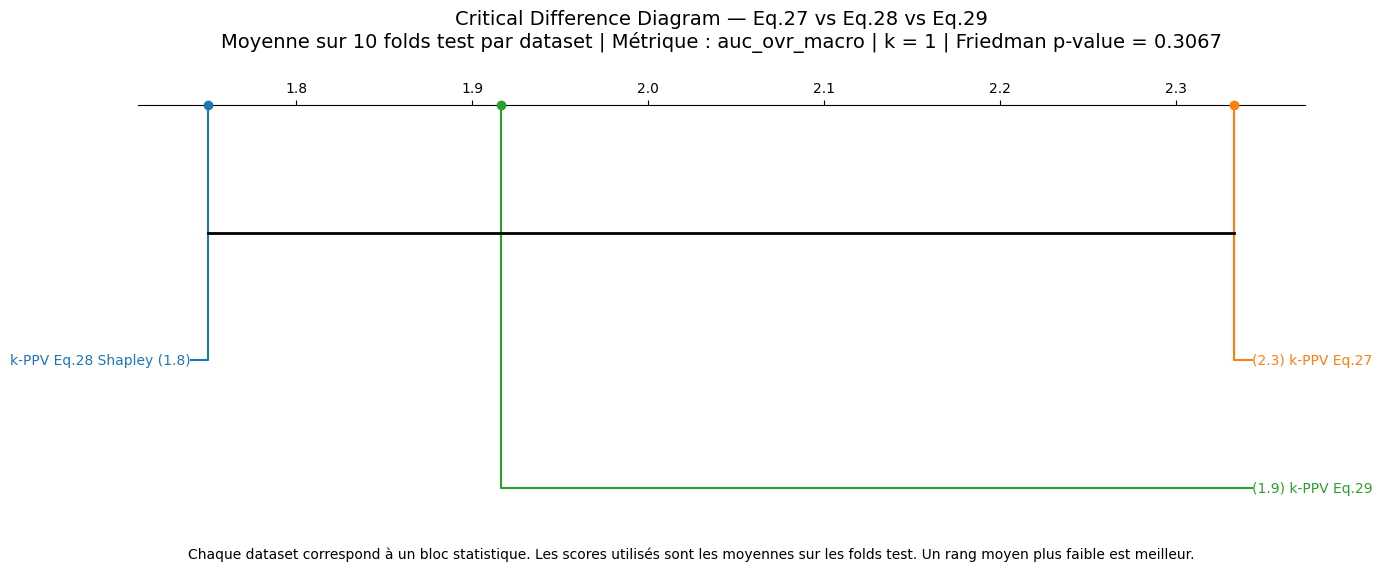


CD GLOBAL SAUVEGARDE
 - khiops_outputs\global_cd_equations\global_critical_difference_diagram_equations_27_28_29_auc_ovr_macro.png
 - khiops_outputs\global_cd_equations\global_cd_equations_mean_10_folds_auc_ovr_macro_long.csv
 - khiops_outputs\global_cd_equations\global_cd_equations_mean_10_folds_auc_ovr_macro_scores_by_dataset.csv
 - khiops_outputs\global_cd_equations\global_cd_equations_ranks_by_dataset_auc_ovr_macro.csv
 - khiops_outputs\global_cd_equations\global_cd_equations_average_ranks_auc_ovr_macro.csv
 - khiops_outputs\global_cd_equations\global_cd_equations_friedman_auc_ovr_macro.csv
 - khiops_outputs\global_cd_equations\global_cd_equations_nemenyi_pvalues_auc_ovr_macro.csv


In [7]:
# ============================================================
# CRITICAL DIFFERENCE DIAGRAM GLOBAL :
# Eq.27 vs Eq.28 Shapley vs Eq.29, ENTRE DATASETS
#
# Chaque score est la moyenne de GLOBAL_CD_METRIC sur les
# N_SPLITS folds test d'un dataset.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import friedmanchisquare, rankdata

import scikit_posthocs as sp


GLOBAL_CD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

representation_labels = {
    "equation_27_weighted_conditional_info": "k-PPV Eq.27",
    "equation_28_shapley_log_odds": "k-PPV Eq.28 Shapley",
    "equation_29_weighted_conditional_info_no_global": "k-PPV Eq.29",
}
expected_methods = [
    "k-PPV Eq.27",
    "k-PPV Eq.28 Shapley",
    "k-PPV Eq.29",
]

global_dataset_results = []

for dataset in DATASETS:
    dataset_name = dataset["name"]

    dataset_file_stem = Path(
        dataset["data_path"]
    ).stem
    
    dataset_output_dir = OUTPUT_ROOT_DIR / dataset_name
    
    knn_results_path = (
        dataset_output_dir
        / (
            f"{dataset_file_stem}_"
            "knn_metrics_train_test_all_folds.csv"
        )
    )
    
    if not knn_results_path.exists():
        raise FileNotFoundError(
            f"Résultats k-PPV introuvables pour le dataset "
            f"'{dataset_name}' :\n{knn_results_path}"
        )

    knn_results = pd.read_csv(
        knn_results_path,
        sep=";",
    )

    required_columns = {
        "fold",
        "split",
        "representation",
        "k",
        GLOBAL_CD_METRIC,
    }

    missing_columns = required_columns - set(knn_results.columns)

    if missing_columns:
        raise ValueError(
            f"Colonnes absentes pour '{dataset_name}' :\n"
            f"{sorted(missing_columns)}"
        )

    # Conservation des résultats k-PPV des folds test,
    # avec une même valeur de k pour les trois équations.
    dataset_test_results = knn_results[
        (knn_results["split"] == "test")
        & (knn_results["k"] == GLOBAL_SELECTED_K)
    ].copy()

    if dataset_test_results.empty:
        raise ValueError(
            f"Aucun résultat test trouvé pour '{dataset_name}' "
            f"et k={GLOBAL_SELECTED_K}."
        )

    dataset_test_results["method"] = (
        dataset_test_results["representation"]
        .map(representation_labels)
    )

    # On exclut explicitement toute représentation non attendue.
    dataset_test_results = dataset_test_results[
        dataset_test_results["method"].isin(expected_methods)
    ].copy()

    found_methods = sorted(
        dataset_test_results["method"].unique().tolist()
    )

    missing_methods = sorted(
        set(expected_methods) - set(found_methods)
    )

    if missing_methods:
        raise ValueError(
            f"Méthodes absentes pour le dataset '{dataset_name}' :\n"
            f"{missing_methods}\n\n"
            f"Méthodes trouvées : {found_methods}"
        )

    # Une équation doit avoir exactement N_SPLITS valeurs,
    # donc une valeur de test par fold.
    fold_counts = (
        dataset_test_results
        .groupby("method")["fold"]
        .nunique()
    )

    invalid_fold_counts = fold_counts[
        fold_counts != N_SPLITS
    ]

    if not invalid_fold_counts.empty:
        raise ValueError(
            f"Nombre de folds incohérent pour '{dataset_name}'.\n"
            f"Attendu : {N_SPLITS}\n"
            f"Trouvé :\n{invalid_fold_counts.to_string()}"
        )

    # Moyenne de la métrique sur les 10 folds test.
    dataset_mean_results = (
        dataset_test_results
        .groupby("method", as_index=False)
        .agg(
            mean_metric=(
                GLOBAL_CD_METRIC,
                "mean",
            ),
            std_metric=(
                GLOBAL_CD_METRIC,
                "std",
            ),
            n_folds=("fold", "nunique"),
        )
    )

    dataset_mean_results.insert(
        0,
        "dataset",
        dataset_name,
    )

    global_dataset_results.append(dataset_mean_results)


# ------------------------------------------------------------
# Tableau long : une ligne = dataset × méthode.
# ------------------------------------------------------------

global_cd_long = pd.concat(
    global_dataset_results,
    ignore_index=True,
)

global_cd_long = global_cd_long[
    [
        "dataset",
        "method",
        "mean_metric",
        "std_metric",
        "n_folds",
    ]
].sort_values(
    by=["dataset", "method"]
).reset_index(
    drop=True
)

global_cd_long_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_mean_{N_SPLITS}_folds_"
        f"{GLOBAL_CD_METRIC}_long.csv"
    )
)

global_cd_long.to_csv(
    global_cd_long_path,
    sep=";",
    index=False,
)


# ------------------------------------------------------------
# Matrice utilisée par Friedman / Nemenyi :
# lignes = datasets ; colonnes = Eq.27, Eq.28, Eq.29.
# ------------------------------------------------------------

scores_by_dataset = global_cd_long.pivot(
    index="dataset",
    columns="method",
    values="mean_metric",
)

scores_by_dataset = scores_by_dataset[
    expected_methods
]

if scores_by_dataset.isna().any().any():
    missing_values = scores_by_dataset.isna().sum()

    raise ValueError(
        "Des scores sont absents dans la matrice globale.\n\n"
        f"{missing_values[missing_values > 0].to_string()}"
    )

if scores_by_dataset.shape[0] < 2:
    raise ValueError(
        "Le CD global nécessite au moins deux datasets."
    )

scores_by_dataset_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_mean_{N_SPLITS}_folds_"
        f"{GLOBAL_CD_METRIC}_scores_by_dataset.csv"
    )
)

scores_by_dataset.to_csv(
    scores_by_dataset_path,
    sep=";",
    index=True,
)

print("=" * 90)
print("SCORES MOYENS PAR DATASET POUR LE CD GLOBAL")
print("=" * 90)
print(
    f"Métrique            : {GLOBAL_CD_METRIC}\n"
    f"Folds moyens         : {N_SPLITS}\n"
    f"k retenu             : {GLOBAL_SELECTED_K}\n"
    f"Nombre de datasets   : {scores_by_dataset.shape[0]}\n"
    f"Nombre de méthodes   : {scores_by_dataset.shape[1]}"
)

display(scores_by_dataset)


# ------------------------------------------------------------
# Rangs par dataset.
#
# Rang 1 = meilleure méthode : la métrique est maximisée.
# ------------------------------------------------------------

ranks_by_dataset = scores_by_dataset.apply(
    lambda row: rankdata(
        -row.to_numpy(dtype=float),
        method="average",
    ),
    axis=1,
    result_type="expand",
)

ranks_by_dataset.columns = scores_by_dataset.columns
ranks_by_dataset.index = scores_by_dataset.index

average_ranks_global = (
    ranks_by_dataset
    .mean(axis=0)
    .sort_values()
)

ranks_by_dataset_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_ranks_by_dataset_"
        f"{GLOBAL_CD_METRIC}.csv"
    )
)

average_ranks_global_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_average_ranks_"
        f"{GLOBAL_CD_METRIC}.csv"
    )
)

ranks_by_dataset.to_csv(
    ranks_by_dataset_path,
    sep=";",
    index=True,
)

average_ranks_global.rename(
    "average_rank"
).to_csv(
    average_ranks_global_path,
    sep=";",
    header=True,
)

print("\n" + "=" * 90)
print("RANGS MOYENS GLOBAUX")
print("Rang faible = meilleure méthode")
print("=" * 90)

display(
    average_ranks_global
    .rename("average_rank")
    .reset_index()
    .rename(columns={"method": "method"})
)


# ------------------------------------------------------------
# Test de Friedman global.
# Les datasets sont les blocs statistiques.
# ------------------------------------------------------------

friedman_statistic, friedman_p_value = friedmanchisquare(
    *[
        scores_by_dataset[method].to_numpy(dtype=float)
        for method in scores_by_dataset.columns
    ]
)

friedman_global_results = pd.DataFrame(
    [
        {
            "metric": GLOBAL_CD_METRIC,
            "selected_k": GLOBAL_SELECTED_K,
            "n_datasets": scores_by_dataset.shape[0],
            "n_methods": scores_by_dataset.shape[1],
            "friedman_statistic": friedman_statistic,
            "friedman_p_value": friedman_p_value,
            "alpha": ALPHA,
            "reject_h0": friedman_p_value < ALPHA,
        }
    ]
)

friedman_global_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_friedman_"
        f"{GLOBAL_CD_METRIC}.csv"
    )
)

friedman_global_results.to_csv(
    friedman_global_path,
    sep=";",
    index=False,
)

print("\n" + "=" * 90)
print("TEST DE FRIEDMAN GLOBAL")
print("=" * 90)

display(friedman_global_results)


# ------------------------------------------------------------
# Test post-hoc de Nemenyi.
# ------------------------------------------------------------

nemenyi_pvalues_global = sp.posthoc_nemenyi_friedman(
    scores_by_dataset
)

nemenyi_pvalues_global = nemenyi_pvalues_global.loc[
    average_ranks_global.index,
    average_ranks_global.index,
]

nemenyi_global_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_cd_equations_nemenyi_pvalues_"
        f"{GLOBAL_CD_METRIC}.csv"
    )
)

nemenyi_pvalues_global.to_csv(
    nemenyi_global_path,
    sep=";",
    index=True,
)

print("\n" + "=" * 90)
print("P-VALUES DU TEST DE NEMENYI GLOBAL")
print("=" * 90)

display(nemenyi_pvalues_global.round(6))


# ------------------------------------------------------------
# Diagramme CD global.
# ------------------------------------------------------------

global_cd_figure_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        f"global_critical_difference_diagram_"
        f"equations_27_28_29_{GLOBAL_CD_METRIC}.png"
    )
)

figure, axis = plt.subplots(
    figsize=(14, 6)
)

sp.critical_difference_diagram(
    ranks=average_ranks_global,
    sig_matrix=nemenyi_pvalues_global,
    ax=axis,
)

axis.set_title(
    (
        "Critical Difference Diagram — Eq.27 vs Eq.28 vs Eq.29\n"
        f"Moyenne sur {N_SPLITS} folds test par dataset | "
        f"Métrique : {GLOBAL_CD_METRIC} | "
        f"k = {GLOBAL_SELECTED_K} | "
        f"Friedman p-value = {friedman_p_value:.4g}"
    ),
    fontsize=14,
    pad=28,
)

figure.text(
    0.5,
    0.01,
    (
        "Chaque dataset correspond à un bloc statistique. "
        "Les scores utilisés sont les moyennes sur les folds test. "
        "Un rang moyen plus faible est meilleur."
    ),
    ha="center",
    fontsize=10,
)

figure.tight_layout(
    rect=[0, 0.07, 1, 0.95]
)

figure.savefig(
    global_cd_figure_path,
    dpi=250,
    bbox_inches="tight",
)

plt.show()

print("\n" + "=" * 90)
print("CD GLOBAL SAUVEGARDE")
print("=" * 90)

print(f" - {global_cd_figure_path}")
print(f" - {global_cd_long_path}")
print(f" - {scores_by_dataset_path}")
print(f" - {ranks_by_dataset_path}")
print(f" - {average_ranks_global_path}")
print(f" - {friedman_global_path}")
print(f" - {nemenyi_global_path}")


In [8]:
runs_summary_path = OUTPUT_ROOT_DIR / "datasets_execution_summary.csv"

runs_summary.to_csv(
    runs_summary_path,
    sep=";",
    index=False,
)

print(f"Synthèse créée :\n - {runs_summary_path}")


Synthèse créée :
 - khiops_outputs\datasets_execution_summary.csv


In [9]:
# ============================================================
# TABLEAU GLOBAL DES PERFORMANCES :
# ACC ET AUC TRAIN / TEST PAR DATASET
#
# Chaque métrique est une moyenne sur les N_SPLITS folds.
#
# Pour k-PPV :
# - test      : score sur le fold test ;
# - train_loo : Leave-One-Out sur le fold train.
#
# Pour SNB :
# - test  : score sur le fold test ;
# - train : score sur le jeu d'apprentissage.
# ============================================================

# ------------------------------------------------------------
# PARAMETRE DE LA METRIQUE AUC A AFFICHER
# ------------------------------------------------------------
#
# "auc_ovr_macro" :
# moyenne non pondérée entre classes ; cohérente avec le CD global.
#
# "auc_ovr_weighted" :
# moyenne pondérée par la fréquence des classes ; plus proche
# de la définition AUC utilisée dans le PDF.
#
# "auc" :
# utilisable seulement pour les datasets binaires.
# ------------------------------------------------------------

SUMMARY_AUC_METRIC = GLOBAL_CD_METRIC
# Exemple pour se rapprocher du protocole du PDF :
# SUMMARY_AUC_METRIC = "auc_ovr_weighted"


# ------------------------------------------------------------
# LIBELLES DES REPRESENTATIONS k-PPV
# ------------------------------------------------------------

representation_labels = {
    "equation_27_weighted_conditional_info": "k-PPV Eq.27",
    "equation_28_shapley_log_odds": "k-PPV Eq.28 Shapley",
    "equation_29_weighted_conditional_info_no_global": "k-PPV Eq.29",
}


def check_expected_folds(dataframe, dataset_name, method_name, split_name):
    """
    Vérifie qu'une méthode possède exactement N_SPLITS folds distincts.
    """
    found_folds = sorted(dataframe["fold"].unique().tolist())

    expected_folds = list(range(1, N_SPLITS + 1))

    if found_folds != expected_folds:
        raise ValueError(
            f"Folds incohérents pour le dataset '{dataset_name}', "
            f"méthode '{method_name}', split '{split_name}'.\n\n"
            f"Folds attendus : {expected_folds}\n"
            f"Folds trouvés  : {found_folds}"
        )


def summarize_method_splits(
    dataset_name,
    method_name,
    test_dataframe,
    train_dataframe,
    auc_metric,
    train_split_label,
):
    """
    Produit une ligne de synthèse contenant les moyennes ACC/AUC
    train et test d'une méthode pour un dataset.
    """

    if test_dataframe.empty:
        raise ValueError(
            f"Aucun résultat test pour '{dataset_name}' / '{method_name}'."
        )

    if train_dataframe.empty:
        raise ValueError(
            f"Aucun résultat train pour '{dataset_name}' / '{method_name}'.\n"
            f"Split train attendu : '{train_split_label}'."
        )

    check_expected_folds(
        test_dataframe,
        dataset_name,
        method_name,
        "test",
    )

    check_expected_folds(
        train_dataframe,
        dataset_name,
        method_name,
        train_split_label,
    )

    required_columns = {
        "accuracy",
        auc_metric,
    }

    missing_test_columns = required_columns - set(test_dataframe.columns)
    missing_train_columns = required_columns - set(train_dataframe.columns)

    if missing_test_columns:
        raise ValueError(
            f"Colonnes absentes des résultats test pour "
            f"'{dataset_name}' / '{method_name}' : "
            f"{sorted(missing_test_columns)}"
        )

    if missing_train_columns:
        raise ValueError(
            f"Colonnes absentes des résultats train pour "
            f"'{dataset_name}' / '{method_name}' : "
            f"{sorted(missing_train_columns)}"
        )

    # Conversion robuste en numérique.
    test_accuracy = pd.to_numeric(
        test_dataframe["accuracy"],
        errors="coerce",
    )

    test_auc = pd.to_numeric(
        test_dataframe[auc_metric],
        errors="coerce",
    )

    train_accuracy = pd.to_numeric(
        train_dataframe["accuracy"],
        errors="coerce",
    )

    train_auc = pd.to_numeric(
        train_dataframe[auc_metric],
        errors="coerce",
    )

    if (
        test_accuracy.isna().any()
        or test_auc.isna().any()
        or train_accuracy.isna().any()
        or train_auc.isna().any()
    ):
        raise ValueError(
            f"Valeur ACC ou AUC manquante pour "
            f"'{dataset_name}' / '{method_name}'."
        )

    return {
        "dataset": dataset_name,
        "method": method_name,
        "n_folds_test": test_dataframe["fold"].nunique(),
        "n_folds_train": train_dataframe["fold"].nunique(),
        "accuracy_test_mean": test_accuracy.mean(),
        "auc_test_mean": test_auc.mean(),
        "accuracy_train_mean": train_accuracy.mean(),
        "auc_train_mean": train_auc.mean(),
        "train_evaluation": train_split_label,
    }


# ------------------------------------------------------------
# LECTURE ET AGRÉGATION DES RESULTATS DE TOUS LES DATASETS
# ------------------------------------------------------------

all_datasets_performance = []

for dataset in DATASETS:

    dataset_name = dataset["name"]

    # Important :
    # les fichiers produits par kppv.ipynb utilisent le stem du fichier,
    # par exemple Adult.txt -> Adult.
    dataset_file_stem = Path(dataset["data_path"]).stem

    dataset_output_dir = OUTPUT_ROOT_DIR / dataset_name

    knn_results_path = (
        dataset_output_dir
        / f"{dataset_file_stem}_knn_metrics_train_test_all_folds.csv"
    )

    snb_results_path = (
        dataset_output_dir
        / f"{dataset_file_stem}_snb_metrics_train_test_all_folds.csv"
    )

    if not knn_results_path.exists():
        raise FileNotFoundError(
            f"Résultats k-PPV introuvables pour '{dataset_name}' :\n"
            f"{knn_results_path}"
        )

    if not snb_results_path.exists():
        raise FileNotFoundError(
            f"Résultats SNB introuvables pour '{dataset_name}' :\n"
            f"{snb_results_path}"
        )

    knn_results = pd.read_csv(
        knn_results_path,
        sep=";",
    )

    snb_results = pd.read_csv(
        snb_results_path,
        sep=";",
    )

    required_knn_columns = {
        "fold",
        "split",
        "representation",
        "k",
        "accuracy",
        SUMMARY_AUC_METRIC,
    }

    required_snb_columns = {
        "fold",
        "split",
        "accuracy",
        SUMMARY_AUC_METRIC,
    }

    missing_knn_columns = required_knn_columns - set(knn_results.columns)
    missing_snb_columns = required_snb_columns - set(snb_results.columns)

    if missing_knn_columns:
        raise ValueError(
            f"Colonnes absentes des résultats k-PPV pour "
            f"'{dataset_name}' :\n{sorted(missing_knn_columns)}"
        )

    if missing_snb_columns:
        raise ValueError(
            f"Colonnes absentes des résultats SNB pour "
            f"'{dataset_name}' :\n{sorted(missing_snb_columns)}"
        )

    # --------------------------------------------------------
    # k-PPV : Eq.27, Eq.28 et Eq.29, pour chaque valeur de k.
    # --------------------------------------------------------

    for representation_name, representation_label in representation_labels.items():

        available_k_values = sorted(
            knn_results.loc[
                knn_results["representation"] == representation_name,
                "k",
            ]
            .dropna()
            .astype(int)
            .unique()
            .tolist()
        )

        if not available_k_values:
            raise ValueError(
                f"Aucun résultat trouvé pour '{dataset_name}' / "
                f"'{representation_name}'."
            )

        for k_value in available_k_values:

            method_name = f"{representation_label} | k={k_value}"

            knn_test = knn_results[
                (knn_results["representation"] == representation_name)
                & (knn_results["k"] == k_value)
                & (knn_results["split"] == "test")
            ].copy()

            knn_train_loo = knn_results[
                (knn_results["representation"] == representation_name)
                & (knn_results["k"] == k_value)
                & (knn_results["split"] == "train_loo")
            ].copy()

            summary_row = summarize_method_splits(
                dataset_name=dataset_name,
                method_name=method_name,
                test_dataframe=knn_test,
                train_dataframe=knn_train_loo,
                auc_metric=SUMMARY_AUC_METRIC,
                train_split_label="train_loo",
            )

            all_datasets_performance.append(summary_row)

    # --------------------------------------------------------
    # SNB
    # --------------------------------------------------------

    snb_test = snb_results[
        snb_results["split"] == "test"
    ].copy()

    snb_train = snb_results[
        snb_results["split"] == "train"
    ].copy()

    summary_row = summarize_method_splits(
        dataset_name=dataset_name,
        method_name="SNB",
        test_dataframe=snb_test,
        train_dataframe=snb_train,
        auc_metric=SUMMARY_AUC_METRIC,
        train_split_label="train",
    )

    all_datasets_performance.append(summary_row)


# ------------------------------------------------------------
# TABLEAU LONG :
# une ligne = dataset × méthode
# ------------------------------------------------------------

performance_long = pd.DataFrame(
    all_datasets_performance
).sort_values(
    by=["dataset", "method"]
).reset_index(
    drop=True
)

performance_long_path = (
    OUTPUT_ROOT_DIR
    / (
        f"performance_train_test_mean_{N_SPLITS}_folds_"
        f"{SUMMARY_AUC_METRIC}_long.csv"
    )
)

performance_long.to_csv(
    performance_long_path,
    sep=";",
    index=False,
)


# ------------------------------------------------------------
# TABLEAU LARGE :
# une ligne = dataset ;
# colonnes = ACC/AUC train/test pour chaque méthode.
# ------------------------------------------------------------

performance_wide = performance_long.pivot(
    index="dataset",
    columns="method",
    values=[
        "accuracy_test_mean",
        "auc_test_mean",
        "accuracy_train_mean",
        "auc_train_mean",
    ],
)

# Colonnes plates et lisibles pour l'export CSV.
performance_wide.columns = [
    f"{method} | {metric}"
    for metric, method in performance_wide.columns
]

# Réorganisation des colonnes :
# pour chaque méthode : ACC test, AUC test, ACC train, AUC train.
ordered_columns = []

methods_order = sorted(
    performance_long["method"].unique().tolist(),
    key=lambda method: (
        0 if method == "SNB" else 1,
        method,
    ),
)

metrics_order = [
    "accuracy_test_mean",
    "auc_test_mean",
    "accuracy_train_mean",
    "auc_train_mean",
]

for method_name in methods_order:
    for metric_name in metrics_order:
        column_name = f"{method_name} | {metric_name}"

        if column_name in performance_wide.columns:
            ordered_columns.append(column_name)

performance_wide = performance_wide[ordered_columns]

# Dernière ligne :
# moyenne non pondérée des scores moyens obtenus sur les datasets.
performance_wide.loc["MOYENNE_DATASETS"] = performance_wide.mean(
    axis=0,
)

performance_wide = performance_wide.reset_index().rename(
    columns={"dataset": "dataset"}
)

performance_wide_path = (
    OUTPUT_ROOT_DIR
    / (
        f"performance_train_test_mean_{N_SPLITS}_folds_"
        f"{SUMMARY_AUC_METRIC}_by_dataset.csv"
    )
)

performance_wide.to_csv(
    performance_wide_path,
    sep=";",
    index=False,
)


# ------------------------------------------------------------
# VERSION POUR AFFICHAGE :
# conversion en pourcentages et arrondi à deux décimales.
# ------------------------------------------------------------

performance_wide_display = performance_wide.copy()

numeric_columns = performance_wide_display.select_dtypes(
    include="number"
).columns

performance_wide_display[numeric_columns] = (
    performance_wide_display[numeric_columns]
    .mul(100)
    .round(2)
)

print("=" * 110)
print("PERFORMANCES MOYENNES TRAIN / TEST PAR DATASET")
print("=" * 110)

print(
    f"AUC utilisée : {SUMMARY_AUC_METRIC}\n"
    f"Nombre de folds moyens : {N_SPLITS}\n"
    "Les valeurs affichées sont des pourcentages.\n\n"
    "Important :\n"
    " - k-PPV train = Leave-One-Out sur les folds train ;\n"
    " - SNB train = prédiction directe sur les folds train ;\n"
    " - MOYENNE_DATASETS = moyenne non pondérée entre datasets."
)

display(performance_wide_display)

print("\nFichiers créés :")
print(f" - Tableau détaillé (format long) : {performance_long_path}")
print(f" - Tableau synthétique par dataset : {performance_wide_path}")


PERFORMANCES MOYENNES TRAIN / TEST PAR DATASET
AUC utilisée : auc_ovr_macro
Nombre de folds moyens : 10
Les valeurs affichées sont des pourcentages.

Important :
 - k-PPV train = Leave-One-Out sur les folds train ;
 - SNB train = prédiction directe sur les folds train ;
 - MOYENNE_DATASETS = moyenne non pondérée entre datasets.


,dataset,SNB | accuracy_test_mean,SNB | auc_test_mean,SNB | accuracy_train_mean,SNB | auc_train_mean,k-PPV Eq.27 | k=1 | accuracy_test_mean,k-PPV Eq.27 | k=1 | auc_test_mean,k-PPV Eq.27 | k=1 | accuracy_train_mean,k-PPV Eq.27 | k=1 | auc_train_mean,k-PPV Eq.27 | k=3 | accuracy_test_mean,...,k-PPV Eq.29 | k=5 | accuracy_train_mean,k-PPV Eq.29 | k=5 | auc_train_mean,k-PPV Eq.29 | k=7 | accuracy_test_mean,k-PPV Eq.29 | k=7 | auc_test_mean,k-PPV Eq.29 | k=7 | accuracy_train_mean,k-PPV Eq.29 | k=7 | auc_train_mean,k-PPV Eq.29 | k=9 | accuracy_test_mean,k-PPV Eq.29 | k=9 | auc_test_mean,k-PPV Eq.29 | k=9 | accuracy_train_mean,k-PPV Eq.29 | k=9 | auc_train_mean
0,Adult,86.91,92.47,86.94,92.53,82.70,76.18,82.73,76.22,84.91,...,85.68,88.25,86.01,89.55,85.99,89.54,86.20,90.24,86.21,90.27
1,Heart,83.33,90.39,86.91,92.88,79.26,78.83,80.62,80.42,80.00,...,83.09,88.59,82.59,87.17,84.32,89.00,81.85,88.86,84.49,89.24
2,Letter,75.50,98.23,76.46,98.49,93.48,96.59,93.43,96.57,92.77,...,93.17,99.20,92.76,99.44,92.72,99.41,92.20,99.56,92.19,99.53
3,Mushroom,99.90,99.99,99.90,99.99,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
4,Pendigits,89.71,99.23,90.51,99.38,97.31,98.52,97.53,98.64,97.61,...,97.68,99.71,97.42,99.76,97.56,99.77,97.21,99.79,97.40,99.81
5,Phoneme,90.83,98.61,92.24,98.98,89.41,92.97,89.87,93.29,91.07,...,91.92,97.83,91.78,98.19,92.05,98.19,91.72,98.30,92.18,98.43
6,Pima,76.43,83.46,78.52,85.37,71.74,69.63,70.26,67.59,72.64,...,75.62,79.56,75.24,79.73,75.26,81.14,75.50,80.88,74.90,81.66
7,Segmentation,94.85,99.53,96.47,99.79,97.14,98.33,97.50,98.54,97.19,...,97.42,99.51,97.19,99.61,97.05,99.62,96.84,99.61,96.76,99.67
8,Shuttle,99.87,100.00,99.89,100.00,99.94,93.60,99.95,96.09,99.93,...,99.95,98.59,99.94,97.00,99.95,98.92,99.94,97.71,99.94,99.28
9,SickEuthyroid,95.00,95.31,95.59,96.34,65.03,76.74,55.99,73.90,62.86,...,53.87,78.42,52.73,77.42,58.81,78.77,57.67,77.72,64.13,79.23



Fichiers créés :
 - Tableau détaillé (format long) : khiops_outputs\performance_train_test_mean_10_folds_auc_ovr_macro_long.csv
 - Tableau synthétique par dataset : khiops_outputs\performance_train_test_mean_10_folds_auc_ovr_macro_by_dataset.csv


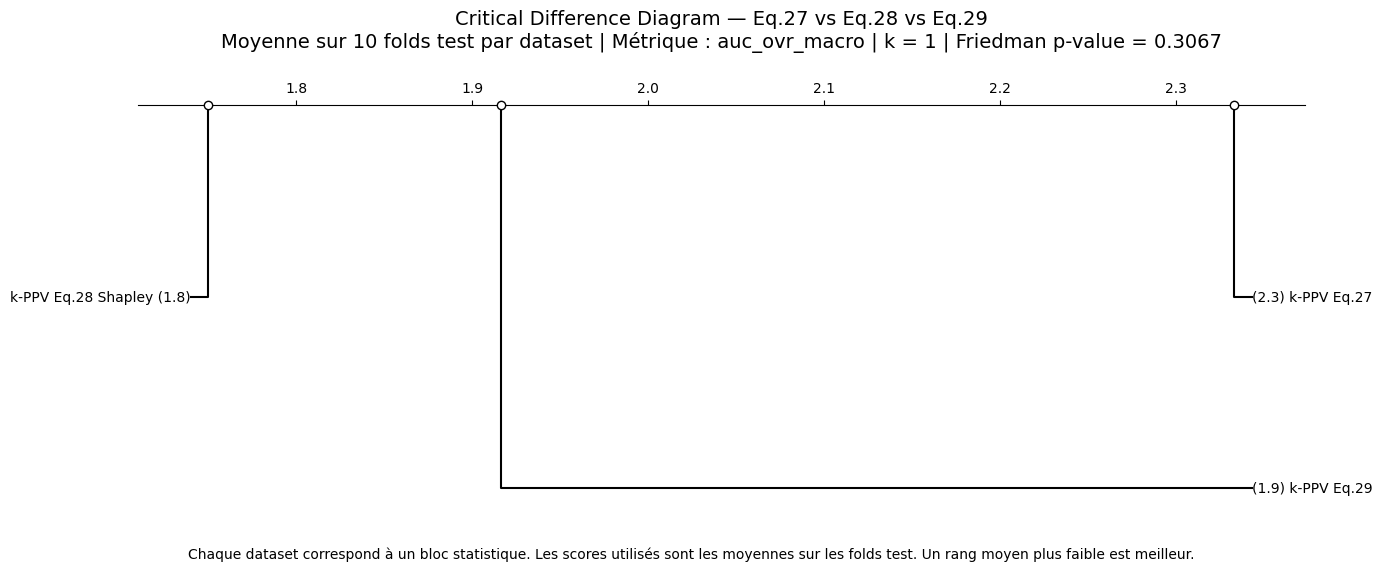

CD GLOBAL NOIR ET BLANC SAUVEGARDE
 - khiops_outputs\global_cd_equations\global_critical_difference_diagram_equations_27_28_29_auc_ovr_macro_black_white.png


In [10]:
# ============================================================
# EXPORT DU CRITICAL DIFFERENCE DIAGRAM GLOBAL EN NOIR ET BLANC
# ============================================================

# Cette cellule suppose que l'Item 7 a déjà été exécuté et que
# les objets suivants existent :
# - average_ranks_global
# - nemenyi_pvalues_global
# - friedman_p_value
# - GLOBAL_CD_OUTPUT_DIR
# - GLOBAL_CD_METRIC
# - GLOBAL_SELECTED_K
# - N_SPLITS

global_cd_black_white_path = (
    GLOBAL_CD_OUTPUT_DIR
    / (
        "global_critical_difference_diagram_"
        f"equations_27_28_29_{GLOBAL_CD_METRIC}_black_white.png"
    )
)

# Création du diagramme avec fond blanc.
figure, axis = plt.subplots(
    figsize=(14, 6),
    facecolor="white",
)

sp.critical_difference_diagram(
    ranks=average_ranks_global,
    sig_matrix=nemenyi_pvalues_global,
    ax=axis,
)

# ------------------------------------------------------------
# Transformation de tous les éléments du diagramme en noir
# et blanc.
# ------------------------------------------------------------

# Segments, axes, raccordements et marqueurs.
for line in axis.get_lines():
    line.set_color("black")
    line.set_markeredgecolor("black")

    # Les marqueurs éventuels restent blancs, bordés de noir.
    if line.get_marker() not in (None, "", "None"):
        line.set_markerfacecolor("white")

# Collections graphiques éventuelles.
for collection in axis.collections:
    try:
        collection.set_color("black")
    except (AttributeError, TypeError):
        pass

    try:
        collection.set_edgecolor("black")
    except (AttributeError, TypeError):
        pass

    try:
        collection.set_facecolor("white")
    except (AttributeError, TypeError):
        pass

# Objets graphiques de type Patch, s'il y en a.
for patch in axis.patches:
    patch.set_edgecolor("black")
    patch.set_facecolor("white")

# Textes et graduations.
for text in axis.texts:
    text.set_color("black")

axis.tick_params(
    axis="both",
    colors="black",
)

for spine in axis.spines.values():
    spine.set_color("black")

axis.set_facecolor("white")

# ------------------------------------------------------------
# Titre et note méthodologique.
# ------------------------------------------------------------

axis.set_title(
    (
        "Critical Difference Diagram — Eq.27 vs Eq.28 vs Eq.29\n"
        f"Moyenne sur {N_SPLITS} folds test par dataset | "
        f"Métrique : {GLOBAL_CD_METRIC} | "
        f"k = {GLOBAL_SELECTED_K} | "
        f"Friedman p-value = {friedman_p_value:.4g}"
    ),
    fontsize=14,
    pad=28,
    color="black",
)

figure.text(
    0.5,
    0.01,
    (
        "Chaque dataset correspond à un bloc statistique. "
        "Les scores utilisés sont les moyennes sur les folds test. "
        "Un rang moyen plus faible est meilleur."
    ),
    ha="center",
    fontsize=10,
    color="black",
)

figure.tight_layout(
    rect=[0, 0.07, 1, 0.95]
)

# Export avec fond blanc explicite.
figure.savefig(
    global_cd_black_white_path,
    dpi=250,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white",
)

plt.show()
plt.close(figure)

print("=" * 90)
print("CD GLOBAL NOIR ET BLANC SAUVEGARDE")
print("=" * 90)
print(f" - {global_cd_black_white_path}")



In [11]:
# ============================================================
# COHERENCE PREDICTIVE LOCALE DES VOISINAGES :
# SYNTHESE GLOBALE DE LocDelta_k POUR CHAQUE VALEUR DE k
#
# Une valeur LocDelta faible indique que les voisins induits
# par une distance ont des profils prédictifs SNB plus proches
# au sens de Delta_1.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import friedmanchisquare, rankdata


# ------------------------------------------------------------
# Valeurs de k à analyser.
#
# Elles reprennent les valeurs transmises à kppv.ipynb :
# K_VALUES = [1, 3, 5, 7]
# ------------------------------------------------------------

LOCAL_DELTA_K_VALUES = sorted(
    {
        int(k)
        for k in K_VALUES
    }
)

if not LOCAL_DELTA_K_VALUES:
    raise ValueError(
        "Aucune valeur de k n'est disponible pour LocDelta."
    )


# ------------------------------------------------------------
# Libellés des trois distances.
# ------------------------------------------------------------

representation_labels = {
    "equation_27_weighted_conditional_info": "k-PPV Eq.27",
    "equation_28_shapley_log_odds": "k-PPV Eq.28 Shapley",
    "equation_29_weighted_conditional_info_no_global": "k-PPV Eq.29",
}

expected_methods = [
    "k-PPV Eq.27",
    "k-PPV Eq.28 Shapley",
    "k-PPV Eq.29",
]


# ------------------------------------------------------------
# Répertoire des résultats globaux LocDelta.
# ------------------------------------------------------------

local_delta_output_dir = (
    OUTPUT_ROOT_DIR
    / "global_local_delta"
)

local_delta_output_dir.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# Lecture des résultats LocDelta de chaque dataset.
#
# Un fichier dataset doit contenir, avec 4 valeurs de k :
#
# 3 distances × 4 k × 10 folds = 120 lignes.
# ------------------------------------------------------------

local_delta_results_by_dataset = {}

for dataset in DATASETS:

    dataset_name = dataset["name"]
    dataset_stem = Path(dataset["data_path"]).stem

    local_delta_path = (
        OUTPUT_ROOT_DIR
        / dataset_name
        / f"{dataset_stem}_local_delta_test_all_folds.csv"
    )

    if not local_delta_path.exists():
        raise FileNotFoundError(
            f"Résultats LocDelta introuvables pour "
            f"'{dataset_name}' :\n{local_delta_path}"
        )

    local_delta_results = pd.read_csv(
        local_delta_path,
        sep=";",
    )

    required_columns = {
        "fold",
        "representation",
        "k",
        "n_evaluated",
        "locdelta",
    }

    missing_columns = (
        required_columns
        - set(local_delta_results.columns)
    )

    if missing_columns:
        raise ValueError(
            f"Colonnes absentes pour '{dataset_name}' :\n"
            f"{sorted(missing_columns)}"
        )

    local_delta_results["k"] = pd.to_numeric(
        local_delta_results["k"],
        errors="raise",
    ).astype(int)

    local_delta_results["n_evaluated"] = pd.to_numeric(
        local_delta_results["n_evaluated"],
        errors="raise",
    )

    local_delta_results["locdelta"] = pd.to_numeric(
        local_delta_results["locdelta"],
        errors="raise",
    )

    if local_delta_results["locdelta"].isna().any():
        raise ValueError(
            f"Valeurs LocDelta manquantes pour '{dataset_name}'."
        )

    available_k_values = sorted(
        local_delta_results["k"]
        .unique()
        .tolist()
    )

    missing_k_values = sorted(
        set(LOCAL_DELTA_K_VALUES)
        - set(available_k_values)
    )

    if missing_k_values:
        raise ValueError(
            f"Valeurs de k absentes pour '{dataset_name}'.\n\n"
            f"k attendus : {LOCAL_DELTA_K_VALUES}\n"
            f"k trouvés  : {available_k_values}\n"
            f"k absents  : {missing_k_values}\n\n"
            "Il faut relancer le pipeline avec "
            "K_VALUES contenant toutes les valeurs de k."
        )

    local_delta_results_by_dataset[
        dataset_name
    ] = local_delta_results


# ------------------------------------------------------------
# Dictionnaire permettant de conserver les objets générés
# pour chaque valeur de k dans la mémoire du notebook.
# ------------------------------------------------------------

all_local_delta_global_summaries = {}


# ============================================================
# BOUCLE : UN TABLEAU ET UN TEST PAR VALEUR DE k
# ============================================================

for LOCAL_DELTA_K in LOCAL_DELTA_K_VALUES:

    local_delta_by_dataset_rows = []

    # --------------------------------------------------------
    # Agrégation par dataset et méthode.
    # --------------------------------------------------------

    for dataset in DATASETS:

        dataset_name = dataset["name"]

        local_delta_results = (
            local_delta_results_by_dataset[dataset_name]
        )

        dataset_local_delta = local_delta_results[
            local_delta_results["k"] == LOCAL_DELTA_K
        ].copy()

        dataset_local_delta["method"] = (
            dataset_local_delta["representation"]
            .map(representation_labels)
        )

        dataset_local_delta = dataset_local_delta[
            dataset_local_delta["method"].isin(
                expected_methods
            )
        ].copy()

        found_methods = set(
            dataset_local_delta["method"].unique()
        )

        missing_methods = (
            set(expected_methods)
            - found_methods
        )

        if missing_methods:
            raise ValueError(
                f"Méthodes absentes pour '{dataset_name}' "
                f"et k={LOCAL_DELTA_K} :\n"
                f"{sorted(missing_methods)}"
            )

        for method_name in expected_methods:

            method_results = dataset_local_delta[
                dataset_local_delta["method"] == method_name
            ].copy()

            found_folds = sorted(
                method_results["fold"]
                .unique()
                .tolist()
            )

            expected_folds = list(
                range(1, N_SPLITS + 1)
            )

            if found_folds != expected_folds:
                raise ValueError(
                    f"Folds incohérents pour "
                    f"'{dataset_name}' / '{method_name}' / "
                    f"k={LOCAL_DELTA_K}.\n\n"
                    f"Folds attendus : {expected_folds}\n"
                    f"Folds trouvés  : {found_folds}"
                )

            if len(method_results) != N_SPLITS:
                raise ValueError(
                    f"Nombre de lignes incohérent pour "
                    f"'{dataset_name}' / '{method_name}' / "
                    f"k={LOCAL_DELTA_K}.\n\n"
                    f"Nombre attendu : {N_SPLITS}\n"
                    f"Nombre trouvé  : {len(method_results)}"
                )

            # Moyenne pondérée par les tailles des folds test.
            #
            # Cela correspond à la moyenne de LocDelta sur
            # toutes les observations test des 10 folds.
            locdelta_weighted_mean = np.average(
                method_results["locdelta"],
                weights=method_results["n_evaluated"],
            )

            local_delta_by_dataset_rows.append(
                {
                    "dataset": dataset_name,
                    "method": method_name,
                    "k": LOCAL_DELTA_K,
                    "locdelta_mean_test": (
                        locdelta_weighted_mean
                    ),
                    "n_test_total": method_results[
                        "n_evaluated"
                    ].sum(),
                    "n_folds": method_results[
                        "fold"
                    ].nunique(),
                }
            )

    # --------------------------------------------------------
    # Tableau long : dataset × méthode.
    # --------------------------------------------------------

    local_delta_long = pd.DataFrame(
        local_delta_by_dataset_rows
    )

    local_delta_long = (
        local_delta_long
        .sort_values(
            by=[
                "dataset",
                "method",
            ]
        )
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Tableau large : une ligne = un dataset.
    # --------------------------------------------------------

    local_delta_scores_by_dataset = (
        local_delta_long
        .pivot(
            index="dataset",
            columns="method",
            values="locdelta_mean_test",
        )
    )

    local_delta_scores_by_dataset = (
        local_delta_scores_by_dataset[
            expected_methods
        ]
    )

    if local_delta_scores_by_dataset.isna().any().any():
        raise ValueError(
            f"Scores LocDelta manquants pour "
            f"k={LOCAL_DELTA_K}."
        )

    # --------------------------------------------------------
    # Tableau de présentation :
    # ajout de la moyenne non pondérée entre datasets.
    # --------------------------------------------------------

    local_delta_scores_display = (
        local_delta_scores_by_dataset.copy()
    )

    local_delta_scores_display.loc[
        "MOYENNE_DATASETS"
    ] = (
        local_delta_scores_by_dataset.mean(axis=0)
    )

    local_delta_scores_display.index.name = "dataset"

    # --------------------------------------------------------
    # Rangs par dataset.
    #
    # Rang 1 = LocDelta minimal = meilleure cohérence locale.
    # --------------------------------------------------------

    local_delta_ranks_by_dataset = (
        local_delta_scores_by_dataset.apply(
            lambda row: rankdata(
                row.to_numpy(dtype=float),
                method="average",
            ),
            axis=1,
            result_type="expand",
        )
    )

    local_delta_ranks_by_dataset.columns = (
        local_delta_scores_by_dataset.columns
    )

    local_delta_ranks_by_dataset.index = (
        local_delta_scores_by_dataset.index
    )

    local_delta_average_ranks = (
        local_delta_ranks_by_dataset
        .mean(axis=0)
        .sort_values()
    )

    # --------------------------------------------------------
    # Test de Friedman :
    # les datasets constituent les blocs statistiques.
    # --------------------------------------------------------

    friedman_statistic_locdelta, friedman_p_value_locdelta = (
        friedmanchisquare(
            *[
                local_delta_scores_by_dataset[
                    method_name
                ].to_numpy(dtype=float)
                for method_name in expected_methods
            ]
        )
    )

    local_delta_friedman_results = pd.DataFrame(
        [
            {
                "k": LOCAL_DELTA_K,
                "n_datasets": len(
                    local_delta_scores_by_dataset
                ),
                "n_methods": len(expected_methods),
                "friedman_statistic": (
                    friedman_statistic_locdelta
                ),
                "friedman_p_value": (
                    friedman_p_value_locdelta
                ),
                "alpha": ALPHA,
                "reject_h0": (
                    friedman_p_value_locdelta < ALPHA
                ),
            }
        ]
    )

    # --------------------------------------------------------
    # Exports spécifiques à la valeur de k.
    # --------------------------------------------------------

    local_delta_long_path = (
        local_delta_output_dir
        / f"local_delta_k_{LOCAL_DELTA_K}_by_dataset_long.csv"
    )

    local_delta_scores_path = (
        local_delta_output_dir
        / f"local_delta_k_{LOCAL_DELTA_K}_scores_by_dataset.csv"
    )

    local_delta_scores_display_path = (
        local_delta_output_dir
        / (
            f"local_delta_k_{LOCAL_DELTA_K}_"
            "scores_by_dataset_with_mean.csv"
        )
    )

    local_delta_ranks_path = (
        local_delta_output_dir
        / f"local_delta_k_{LOCAL_DELTA_K}_ranks_by_dataset.csv"
    )

    local_delta_average_ranks_path = (
        local_delta_output_dir
        / f"local_delta_k_{LOCAL_DELTA_K}_average_ranks.csv"
    )

    local_delta_friedman_path = (
        local_delta_output_dir
        / f"local_delta_k_{LOCAL_DELTA_K}_friedman.csv"
    )

    local_delta_long.to_csv(
        local_delta_long_path,
        sep=";",
        index=False,
    )

    local_delta_scores_by_dataset.to_csv(
        local_delta_scores_path,
        sep=";",
        index=True,
    )

    local_delta_scores_display.to_csv(
        local_delta_scores_display_path,
        sep=";",
        index=True,
    )

    local_delta_ranks_by_dataset.to_csv(
        local_delta_ranks_path,
        sep=";",
        index=True,
    )

    local_delta_average_ranks.rename(
        "average_rank"
    ).to_csv(
        local_delta_average_ranks_path,
        sep=";",
        header=True,
    )

    local_delta_friedman_results.to_csv(
        local_delta_friedman_path,
        sep=";",
        index=False,
    )

    # --------------------------------------------------------
    # Affichage pour la valeur de k courante.
    # --------------------------------------------------------

    print("\n" + "=" * 100)
    print(
        "COHERENCE PREDICTIVE LOCALE DES VOISINAGES "
        f"— k = {LOCAL_DELTA_K}"
    )
    print("=" * 100)

    print(
        f"Nombre de datasets : "
        f"{len(local_delta_scores_by_dataset)}\n"
        f"Friedman p-value   : "
        f"{friedman_p_value_locdelta:.6g}\n\n"
        "Interprétation : une valeur LocDelta faible "
        "indique des voisinages plus cohérents "
        "prédictivement."
    )

    print(
        "\nDISPERSION PREDICTIVE LOCALE MOYENNE "
        "PAR DATASET"
    )

    display(
        local_delta_scores_display.round(6)
    )

    print("\nRangs par dataset :")
    display(local_delta_ranks_by_dataset)

    print("\nRangs moyens :")
    display(
        local_delta_average_ranks
        .rename("average_rank")
        .reset_index()
    )

    print("\nFichiers créés :")
    print(f" - {local_delta_long_path}")
    print(f" - {local_delta_scores_path}")
    print(f" - {local_delta_scores_display_path}")
    print(f" - {local_delta_ranks_path}")
    print(f" - {local_delta_average_ranks_path}")
    print(f" - {local_delta_friedman_path}")

    # Conservation des résultats dans la mémoire Python.
    all_local_delta_global_summaries[
        LOCAL_DELTA_K
    ] = {
        "scores_by_dataset": (
            local_delta_scores_by_dataset
        ),
        "scores_by_dataset_with_mean": (
            local_delta_scores_display
        ),
        "ranks_by_dataset": (
            local_delta_ranks_by_dataset
        ),
        "average_ranks": (
            local_delta_average_ranks
        ),
        "friedman": (
            local_delta_friedman_results
        ),
    }



COHERENCE PREDICTIVE LOCALE DES VOISINAGES — k = 1
Nombre de datasets : 12
Friedman p-value   : 0.124514

Interprétation : une valeur LocDelta faible indique des voisinages plus cohérents prédictivement.

DISPERSION PREDICTIVE LOCALE MOYENNE PAR DATASET


method,k-PPV Eq.27,k-PPV Eq.28 Shapley,k-PPV Eq.29
dataset,,,
Adult,0.115522,0.051642,0.103844
Heart,0.165267,0.165432,0.165763
Letter,10.804814,10.224442,10.473468
Mushroom,0.000080,0.000055,0.000103
Pendigits,3.629853,3.656265,3.737777
Phoneme,1.629522,1.686241,1.703773
Pima,0.039607,0.030128,0.035987
Segmentation,0.890615,0.870683,0.900597
Shuttle,0.007212,0.005564,0.005263



Rangs par dataset :


method,k-PPV Eq.27,k-PPV Eq.28 Shapley,k-PPV Eq.29
dataset,,,
Adult,3.0,1.0,2.0
Heart,1.0,2.0,3.0
Letter,3.0,1.0,2.0
Mushroom,2.0,1.0,3.0
Pendigits,1.0,2.0,3.0
Phoneme,1.0,2.0,3.0
Pima,3.0,1.0,2.0
Segmentation,2.0,1.0,3.0
Shuttle,3.0,2.0,1.0



Rangs moyens :


,method,average_rank
0,k-PPV Eq.28 Shapley,1.583333
1,k-PPV Eq.27,2.000000
2,k-PPV Eq.29,2.416667


... (21 outputs left out)

method,k-PPV Eq.27,k-PPV Eq.28 Shapley,k-PPV Eq.29
dataset,,,
Adult,3.0,1.0,2.0
Heart,2.0,1.0,3.0
Letter,3.0,1.0,2.0
Mushroom,3.0,1.0,2.0
Pendigits,1.0,2.0,3.0
Phoneme,1.0,2.0,3.0
Pima,3.0,1.0,2.0
Segmentation,2.0,1.0,3.0
Shuttle,3.0,2.0,1.0



Rangs moyens :


,method,average_rank
0,k-PPV Eq.28 Shapley,1.333333
1,k-PPV Eq.27,2.333333
2,k-PPV Eq.29,2.333333



Fichiers créés :
 - khiops_outputs\global_local_delta\local_delta_k_9_by_dataset_long.csv
 - khiops_outputs\global_local_delta\local_delta_k_9_scores_by_dataset.csv
 - khiops_outputs\global_local_delta\local_delta_k_9_scores_by_dataset_with_mean.csv
 - khiops_outputs\global_local_delta\local_delta_k_9_ranks_by_dataset.csv
 - khiops_outputs\global_local_delta\local_delta_k_9_average_ranks.csv
 - khiops_outputs\global_local_delta\local_delta_k_9_friedman.csv


In [3]:
# pour faire le loc_agre

In [10]:
# ============================================================
# LocAgree_k : STABILITE LOCALE DE LA CLASSE PREDITE PAR LE SNB
#
# Cellule autonome : ne dépend pas des objets créés dans les
# cellules précédentes du notebook.
#
# Pour chaque dataset, fold, distance et valeur de k :
#
# LocAgree_k(d) =
# moyenne, sur les observations test D et leurs k voisins D',
# de l'indicatrice :
#
#     1[ classe_SNB(D) == classe_SNB(D') ]
#
# Une valeur élevée est préférable.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import friedmanchisquare, rankdata
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors

from khiops.sklearn import KhiopsClassifier


# ------------------------------------------------------------
# PARAMETRES AUTONOMES
# ------------------------------------------------------------

OUTPUT_ROOT_DIR_LOCAGREE = Path("khiops_outputs")

N_SPLITS_LOCAGREE = 10
RANDOM_STATE_LOCAGREE = 42

# Vous pouvez réduire temporairement à [1] pour tester la cellule.
K_VALUES_LOCAGREE = [1, 3, 5, 7, 9]

# Seuil seulement utilisé pour l'interprétation de Friedman.
ALPHA_LOCAGREE = 0.05

DATASETS_LOCAGREE = [
    {"name": "Pima",          "data_path": "Pima.txt",          "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Vehicle",       "data_path": "Vehicle.txt",       "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Segmentation",  "data_path": "Segmentation.txt",  "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Waveform",      "data_path": "Waveform.txt",      "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Mushroom",      "data_path": "Mushroom.txt",      "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Pendigits",     "data_path": "Pendigits.txt",     "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Adult",         "data_path": "Adult.txt",         "target_col": "class", "sep": "\t", "id_col": None},
    {"name": "SickEuthyroid", "data_path": "SickEuthyroid.txt", "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Letter",        "data_path": "Letter.txt",        "target_col": "lettr", "sep": "\t", "id_col": None},
    {"name": "Phoneme",       "data_path": "Phoneme.txt",       "target_col": "g",     "sep": "\t", "id_col": "speaker"},
    {"name": "Shuttle",       "data_path": "Shuttle.txt",       "target_col": "Class", "sep": "\t", "id_col": None},
    {"name": "Heart",         "data_path": "Heart.txt",         "target_col": "Class", "sep": "\t", "id_col": None},
]

REPRESENTATIONS_LOCAGREE = {
    "equation_27_weighted_conditional_info": "d1global (Eq.27)",
    "equation_28_shapley_log_odds": "d1shap (Eq.28)",
    "equation_29_weighted_conditional_info_no_global": "d1SNB (Eq.29)",
}


# ------------------------------------------------------------
# FONCTIONS UTILITAIRES
# ------------------------------------------------------------

def read_csv_semicolon(path):
    """Lecture robuste des fichiers produits par le pipeline."""
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"Fichier introuvable :\n{path.resolve()}")

    return pd.read_csv(path, sep=";")


def prepare_dataset_for_cv(dataset_config):
    """
    Reproduit le prétraitement des notebooks précédents afin de
    reconstruire exactement les mêmes folds stratifiés.
    """

    data_path = Path(dataset_config["data_path"])
    target_col = dataset_config["target_col"]
    sep = dataset_config["sep"]
    id_col = dataset_config["id_col"]

    if not data_path.exists():
        raise FileNotFoundError(
            f"Fichier de données introuvable :\n{data_path.resolve()}"
        )

    df = pd.read_csv(data_path, sep=sep)
    df.columns = df.columns.str.strip()

    if target_col not in df.columns:
        raise ValueError(
            f"Colonne cible absente pour {dataset_config['name']} : "
            f"'{target_col}'.\nColonnes : {df.columns.tolist()}"
        )

    # Même nettoyage que les notebooks MakeCI et kppv.
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .replace({"?": pd.NA, "": pd.NA})
        )

    df = df.dropna(subset=[target_col]).copy()

    if id_col is not None:
        if id_col not in df.columns:
            raise ValueError(
                f"Colonne identifiant absente pour {dataset_config['name']} : "
                f"'{id_col}'"
            )

        ids = df[id_col].copy()
        df_model = df.drop(columns=[id_col]).copy()

    else:
        ids = pd.Series(df.index, index=df.index, name="row_id")
        df_model = df.copy()

    X = df_model.drop(columns=[target_col]).copy()
    y_raw = df_model[target_col].copy()

    # Conservation de la même logique de type pour la cible.
    if pd.api.types.is_numeric_dtype(y_raw):

        y_numeric = pd.to_numeric(y_raw, errors="raise")

        if (y_numeric.dropna() % 1 == 0).all():
            y = y_numeric.astype("int64")
        else:
            y = y_numeric.astype("float64")

    else:
        y = pd.Series(
            y_raw.astype("string").str.strip().to_numpy(dtype=str),
            index=y_raw.index,
            name=target_col,
            dtype=object,
        )

    y.name = target_col

    # Compatibilité Khiops / Pandas.
    for col in X.columns:
        if (
            pd.api.types.is_string_dtype(X[col])
            or isinstance(X[col].dtype, pd.StringDtype)
        ):
            X[col] = X[col].astype(object)

    if y.value_counts().min() < N_SPLITS_LOCAGREE:
        raise ValueError(
            f"{dataset_config['name']} : classe minoritaire insuffisante "
            f"pour {N_SPLITS_LOCAGREE} folds."
        )

    return X, y, ids


def validate_numeric_matrix(dataframe, columns, context):
    """Extrait et valide une matrice numérique sans valeurs manquantes."""

    if not columns:
        raise ValueError(f"Aucune colonne détectée dans : {context}")

    matrix = dataframe[columns].apply(pd.to_numeric, errors="raise")

    if matrix.isna().any().any():
        raise ValueError(f"Valeurs manquantes dans : {context}")

    matrix_array = matrix.to_numpy(dtype=float)

    if not np.isfinite(matrix_array).all():
        raise ValueError(f"Valeurs infinies détectées dans : {context}")

    return matrix_array


def compute_locagree_for_representation(
    X_train_representation,
    X_test_representation,
    snb_predictions_train,
    snb_predictions_test,
    k_values,
):
    """
    Calcule LocAgree_k pour une représentation donnée.

    Pour chaque observation test :
      - recherche les k plus proches voisins parmi les individus train ;
      - compare la classe prédite par le SNB pour l'observation test
        avec celle prédite par le SNB pour chacun de ses voisins train.
    """

    X_train_representation = np.asarray(
        X_train_representation,
        dtype=float,
    )

    X_test_representation = np.asarray(
        X_test_representation,
        dtype=float,
    )

    snb_predictions_train = np.asarray(snb_predictions_train)
    snb_predictions_test = np.asarray(snb_predictions_test)

    if X_train_representation.shape[0] != len(snb_predictions_train):
        raise ValueError(
            "Incohérence entre représentation train et prédictions SNB train."
        )

    if X_test_representation.shape[0] != len(snb_predictions_test):
        raise ValueError(
            "Incohérence entre représentation test et prédictions SNB test."
        )

    max_k = max(k_values)

    if len(X_train_representation) < max_k:
        raise ValueError(
            f"Nombre de voisins demandé trop grand : "
            f"n_train={len(X_train_representation)}, k_max={max_k}."
        )

    neighbors = NearestNeighbors(
        n_neighbors=max_k,
        metric="manhattan",
        algorithm="auto",
    )

    neighbors.fit(X_train_representation)

    _, neighbor_indices = neighbors.kneighbors(X_test_representation)

    # Forme : (n_test, max_k).
    #
    # Pour chaque observation test et chacun de ses voisins,
    # True si le SNB prédit la même classe.
    same_snb_class_by_neighbor = (
        snb_predictions_test[:, np.newaxis]
        == snb_predictions_train[neighbor_indices]
    )

    locagree_by_k = {}

    for k in k_values:

        # Moyenne sur les k voisins, puis sur toutes les observations test.
        locagree = same_snb_class_by_neighbor[:, :k].mean()

        locagree_by_k[k] = float(locagree)

    return locagree_by_k


# ------------------------------------------------------------
# CALCULS PAR DATASET ET PAR FOLD
# ------------------------------------------------------------

all_locagree_fold_results = []

for dataset in DATASETS_LOCAGREE:

    dataset_name = dataset["name"]
    dataset_stem = Path(dataset["data_path"]).stem
    target_col = dataset["target_col"]

    print("\n" + "=" * 100)
    print(f"LocAgree — DATASET : {dataset_name}")
    print("=" * 100)

    X, y, ids = prepare_dataset_for_cv(dataset)

    cv = StratifiedKFold(
        n_splits=N_SPLITS_LOCAGREE,
        shuffle=True,
        random_state=RANDOM_STATE_LOCAGREE,
    )

    dataset_output_dir = OUTPUT_ROOT_DIR_LOCAGREE / dataset_name

    for fold_number, (train_index, test_index) in enumerate(
        cv.split(X, y),
        start=1,
    ):

        print(f"  Fold {fold_number}/{N_SPLITS_LOCAGREE}")

        fold_dir = dataset_output_dir / f"fold_{fold_number:02d}"

        # ----------------------------------------------------
        # Reconstruction du train/test brut du fold.
        # ----------------------------------------------------

        X_train_raw = X.iloc[train_index].copy()
        X_test_raw = X.iloc[test_index].copy()

        y_train_raw = y.iloc[train_index].copy()

        # ----------------------------------------------------
        # Lecture des représentations déjà exportées.
        # ----------------------------------------------------

        ci_train_path = (
            fold_dir
            / f"{dataset_stem}_train_fold_{fold_number:02d}_conditional_info_weighted.csv"
        )

        ci_test_path = (
            fold_dir
            / f"{dataset_stem}_test_fold_{fold_number:02d}_conditional_info_weighted.csv"
        )

        shap_train_path = (
            fold_dir
            / f"{dataset_stem}_train_fold_{fold_number:02d}_shapley.csv"
        )

        shap_test_path = (
            fold_dir
            / f"{dataset_stem}_test_fold_{fold_number:02d}_shapley.csv"
        )

        ci_train = read_csv_semicolon(ci_train_path)
        ci_test = read_csv_semicolon(ci_test_path)

        shap_train = read_csv_semicolon(shap_train_path)
        shap_test = read_csv_semicolon(shap_test_path)

        # Contrôle minimal des tailles.
        if len(ci_train) != len(X_train_raw):
            raise ValueError(
                f"{dataset_name}, fold {fold_number} : "
                "taille CI train incohérente."
            )

        if len(ci_test) != len(X_test_raw):
            raise ValueError(
                f"{dataset_name}, fold {fold_number} : "
                "taille CI test incohérente."
            )

        if len(shap_train) != len(X_train_raw):
            raise ValueError(
                f"{dataset_name}, fold {fold_number} : "
                "taille Shapley train incohérente."
            )

        if len(shap_test) != len(X_test_raw):
            raise ValueError(
                f"{dataset_name}, fold {fold_number} : "
                "taille Shapley test incohérente."
            )

        # ----------------------------------------------------
        # Construction des trois représentations.
        # ----------------------------------------------------

        weighted_ci_columns = [
            column
            for column in ci_train.columns
            if column.startswith("weighted_")
        ]

        global_term_column = "global_log_p_D_weighted_x_J"

        if global_term_column not in ci_train.columns:
            raise ValueError(
                f"{dataset_name}, fold {fold_number} : "
                f"colonne absente : {global_term_column}"
            )

        shapley_columns = [
            column
            for column in shap_train.columns
            if column.startswith("shapley_")
        ]

        # Eq.27 : coordonnées Conditional Info pondérées
        #       + terme global J log p_w(D).
        X_train_eq27 = validate_numeric_matrix(
            ci_train,
            weighted_ci_columns + [global_term_column],
            context=f"{dataset_name}, fold {fold_number}, Eq.27 train",
        )

        X_test_eq27 = validate_numeric_matrix(
            ci_test,
            weighted_ci_columns + [global_term_column],
            context=f"{dataset_name}, fold {fold_number}, Eq.27 test",
        )

        # Eq.28 : vecteur détaillé des valeurs de Shapley.
        X_train_eq28 = validate_numeric_matrix(
            shap_train,
            shapley_columns,
            context=f"{dataset_name}, fold {fold_number}, Eq.28 train",
        )

        X_test_eq28 = validate_numeric_matrix(
            shap_test,
            shapley_columns,
            context=f"{dataset_name}, fold {fold_number}, Eq.28 test",
        )

        # Eq.29 : coordonnées Conditional Info pondérées seules.
        X_train_eq29 = validate_numeric_matrix(
            ci_train,
            weighted_ci_columns,
            context=f"{dataset_name}, fold {fold_number}, Eq.29 train",
        )

        X_test_eq29 = validate_numeric_matrix(
            ci_test,
            weighted_ci_columns,
            context=f"{dataset_name}, fold {fold_number}, Eq.29 test",
        )

        representations_by_name = {
            "equation_27_weighted_conditional_info": (
                X_train_eq27,
                X_test_eq27,
            ),
            "equation_28_shapley_log_odds": (
                X_train_eq28,
                X_test_eq28,
            ),
            "equation_29_weighted_conditional_info_no_global": (
                X_train_eq29,
                X_test_eq29,
            ),
        }

        # ----------------------------------------------------
        # Apprentissage du SNB du fold et prédictions.
        #
        # Ces prédictions définissent uniquement LocAgree ;
        # les véritables classes y ne sont PAS utilisées dans
        # le calcul de l'accord local.
        # ----------------------------------------------------

        snb_output_dir = (
            fold_dir / "locagree_snb_evaluation_classifier"
        )

        snb_classifier = KhiopsClassifier(
            n_trees=0,
            n_pairs=0,
            output_dir=str(snb_output_dir),
        )

        snb_classifier.fit(X_train_raw, y_train_raw)

        snb_predictions_train = np.asarray(
            snb_classifier.predict(X_train_raw)
        )

        snb_predictions_test = np.asarray(
            snb_classifier.predict(X_test_raw)
        )

        # ----------------------------------------------------
        # LocAgree pour les trois distances.
        # ----------------------------------------------------

        for representation_name, (
            X_train_representation,
            X_test_representation,
        ) in representations_by_name.items():

            locagree_by_k = compute_locagree_for_representation(
                X_train_representation=X_train_representation,
                X_test_representation=X_test_representation,
                snb_predictions_train=snb_predictions_train,
                snb_predictions_test=snb_predictions_test,
                k_values=K_VALUES_LOCAGREE,
            )

            for k, locagree_value in locagree_by_k.items():

                all_locagree_fold_results.append(
                    {
                        "dataset": dataset_name,
                        "fold": fold_number,
                        "representation": representation_name,
                        "method": REPRESENTATIONS_LOCAGREE[
                            representation_name
                        ],
                        "k": k,
                        "n_train": len(X_train_raw),
                        "n_test": len(X_test_raw),
                        "locagree": locagree_value,
                    }
                )


# ------------------------------------------------------------
# RESULTATS DETAILLES PAR FOLD
# ------------------------------------------------------------

locagree_fold_results = pd.DataFrame(all_locagree_fold_results)

locagree_fold_results = locagree_fold_results.sort_values(
    by=["dataset", "k", "representation", "fold"]
).reset_index(drop=True)

print("\n" + "=" * 100)
print("LocAgree — RESULTATS DETAILLES PAR FOLD")
print("=" * 100)

display(locagree_fold_results.round(6))


# ------------------------------------------------------------
# SYNTHESE : MOYENNE PONDEREE PAR LA TAILLE DES FOLDS TEST
#
# Puisque chaque observation apparaît une fois en test dans une
# 10-fold CV, cette moyenne correspond à l'accord calculé sur
# l'ensemble des observations test des 10 folds.
# ------------------------------------------------------------

locagree_dataset_rows = []

for (dataset_name, method_name, k_value), group in (
    locagree_fold_results.groupby(["dataset", "method", "k"])
):

    locagree_weighted_mean = np.average(
        group["locagree"],
        weights=group["n_test"],
    )

    locagree_dataset_rows.append(
        {
            "dataset": dataset_name,
            "method": method_name,
            "k": k_value,
            "locagree_mean_test": locagree_weighted_mean,
            "n_test_total": group["n_test"].sum(),
            "n_folds": group["fold"].nunique(),
        }
    )

locagree_by_dataset = pd.DataFrame(locagree_dataset_rows)

locagree_by_dataset = locagree_by_dataset.sort_values(
    by=["k", "dataset", "method"]
).reset_index(drop=True)


# ------------------------------------------------------------
# TABLEAUX ET FRIEDMAN PAR VALEUR DE k
#
# Ici, contrairement à LocDelta :
# - LocAgree élevé = meilleur voisinage ;
# - les rangs sont donc calculés sur -LocAgree.
# ------------------------------------------------------------

locagree_global_results = []

for k_value in K_VALUES_LOCAGREE:

    current_results = locagree_by_dataset[
        locagree_by_dataset["k"] == k_value
    ].copy()

    scores_by_dataset_locagree = current_results.pivot(
        index="dataset",
        columns="method",
        values="locagree_mean_test",
    )

    expected_methods_locagree = list(
        REPRESENTATIONS_LOCAGREE.values()
    )

    scores_by_dataset_locagree = scores_by_dataset_locagree[
        expected_methods_locagree
    ]

    # Rang 1 = meilleure valeur LocAgree, donc plus élevée.
    ranks_by_dataset_locagree = scores_by_dataset_locagree.apply(
        lambda row: rankdata(
            -row.to_numpy(dtype=float),
            method="average",
        ),
        axis=1,
        result_type="expand",
    )

    ranks_by_dataset_locagree.columns = scores_by_dataset_locagree.columns
    ranks_by_dataset_locagree.index = scores_by_dataset_locagree.index

    average_ranks_locagree = (
        ranks_by_dataset_locagree
        .mean(axis=0)
        .sort_values()
    )

    friedman_statistic, friedman_p_value = friedmanchisquare(
        *[
            scores_by_dataset_locagree[method].to_numpy(dtype=float)
            for method in expected_methods_locagree
        ]
    )

    print("\n" + "=" * 100)
    print(f"LocAgree — SYNTHESE GLOBALE — k = {k_value}")
    print("=" * 100)
    print(
        f"Nombre de datasets : {len(scores_by_dataset_locagree)}\n"
        f"Friedman p-value   : {friedman_p_value:.6g}\n"
        f"Seuil alpha         : {ALPHA_LOCAGREE}\n\n"
        "Interprétation : une valeur LocAgree élevée indique "
        "que les voisins partagent plus souvent la même classe "
        "prédite par le SNB."
    )

    print("\nLocAgree moyen par dataset :")
    scores_display = scores_by_dataset_locagree.copy()
    scores_display.loc["MOYENNE_DATASETS"] = (
        scores_by_dataset_locagree.mean(axis=0)
    )
    display(scores_display.round(6))

    print("\nRangs par dataset (rang 1 = meilleur LocAgree) :")
    display(ranks_by_dataset_locagree)

    print("\nRangs moyens :")
    display(
        average_ranks_locagree
        .rename("average_rank")
        .reset_index()
        .rename(columns={"index": "method"})
    )

    locagree_global_results.append(
        {
            "k": k_value,
            "n_datasets": len(scores_by_dataset_locagree),
            "friedman_statistic": friedman_statistic,
            "friedman_p_value": friedman_p_value,
            "alpha": ALPHA_LOCAGREE,
            "reject_h0": friedman_p_value < ALPHA_LOCAGREE,
            "best_method_by_average_rank": average_ranks_locagree.index[0],
            "best_average_rank": average_ranks_locagree.iloc[0],
        }
    )


# ------------------------------------------------------------
# BILAN FINAL SUR LES VALEURS DE k
# ------------------------------------------------------------

locagree_friedman_summary = pd.DataFrame(locagree_global_results)

print("\n" + "=" * 100)
print("LocAgree — BILAN DES TESTS DE FRIEDMAN")
print("=" * 100)

display(locagree_friedman_summary.round(6))



LocAgree — DATASET : Pima
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Vehicle
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Segmentation
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Waveform
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Mushroom
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Pendigits
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10
  Fold 6/10
  Fold 7/10
  Fold 8/10
  Fold 9/10
  Fold 10/10

LocAgree — DATASET : Adult
  Fold 1/10
  Fold 2/10
  Fold 3/10
  Fold 4/10
  Fold 5/10


,dataset,fold,representation,method,k,n_train,n_test,locagree
0,Adult,1,equation_27_weighted_conditional_info,d1global (Eq.27),1,43957,4885,0.988127
1,Adult,2,equation_27_weighted_conditional_info,d1global (Eq.27),1,43957,4885,0.993040
2,Adult,3,equation_27_weighted_conditional_info,d1global (Eq.27),1,43958,4884,0.994472
3,Adult,4,equation_27_weighted_conditional_info,d1global (Eq.27),1,43958,4884,0.994267
4,Adult,5,equation_27_weighted_conditional_info,d1global (Eq.27),1,43958,4884,0.991605
...,...,...,...,...,...,...,...,...
1795,Waveform,6,equation_29_weighted_conditional_info_no_global,d1SNB (Eq.29),9,4500,500,0.849556
1796,Waveform,7,equation_29_weighted_conditional_info_no_global,d1SNB (Eq.29),9,4500,500,0.829778
1797,Waveform,8,equation_29_weighted_conditional_info_no_global,d1SNB (Eq.29),9,4500,500,0.827556
1798,Waveform,9,equation_29_weighted_conditional_info_no_global,d1SNB (Eq.29),9,4500,500,0.863778



LocAgree — SYNTHESE GLOBALE — k = 1
Nombre de datasets : 12
Friedman p-value   : 0.0911967
Seuil alpha         : 0.05

Interprétation : une valeur LocAgree élevée indique que les voisins partagent plus souvent la même classe prédite par le SNB.

LocAgree moyen par dataset :


method,d1global (Eq.27),d1shap (Eq.28),d1SNB (Eq.29)
dataset,,,
Adult,0.992732,0.997666,0.994677
Heart,0.944444,0.959259,0.962963
Letter,0.857950,0.865500,0.865450
Mushroom,1.000000,1.000000,1.000000
Pendigits,0.951965,0.953239,0.951783
Phoneme,0.952381,0.954451,0.953860
Pima,0.990885,0.993490,0.993490
Segmentation,0.974026,0.973593,0.972727
Shuttle,0.999759,0.999759,0.999810



Rangs par dataset (rang 1 = meilleur LocAgree) :


method,d1global (Eq.27),d1shap (Eq.28),d1SNB (Eq.29)
dataset,,,
Adult,3.0,1.0,2.0
Heart,3.0,2.0,1.0
Letter,3.0,1.0,2.0
Mushroom,2.0,2.0,2.0
Pendigits,2.0,1.0,3.0
Phoneme,3.0,1.0,2.0
Pima,3.0,1.5,1.5
Segmentation,1.0,2.0,3.0
Shuttle,2.5,2.5,1.0


... (24 outputs left out)


Rangs moyens :


,method,average_rank
0,d1shap (Eq.28),1.166667
1,d1SNB (Eq.29),2.083333
2,d1global (Eq.27),2.750000



LocAgree — BILAN DES TESTS DE FRIEDMAN


,k,n_datasets,friedman_statistic,friedman_p_value,alpha,reject_h0,best_method_by_average_rank,best_average_rank
0,1,12,4.789474,0.091197,0.05,False,d1shap (Eq.28),1.583333
1,3,12,6.727273,0.034609,0.05,True,d1shap (Eq.28),1.666667
2,5,12,14.363636,0.000760,0.05,True,d1shap (Eq.28),1.416667
3,7,12,12.697674,0.001749,0.05,True,d1shap (Eq.28),1.291667
4,9,12,16.545455,0.000255,0.05,True,d1shap (Eq.28),1.166667


LocAgree MOYEN SUR LES 12 DATASETS
Une valeur élevée indique que les voisins partagent plus fréquemment la même classe prédite par le SNB.


method,d1global (Eq.27),d1shap (Eq.28),d1SNB (Eq.29)
k,,,
1,95.091,95.490,95.347
3,94.012,94.636,94.419
5,93.384,94.128,93.848
7,92.909,93.674,93.393
9,92.519,93.391,93.052


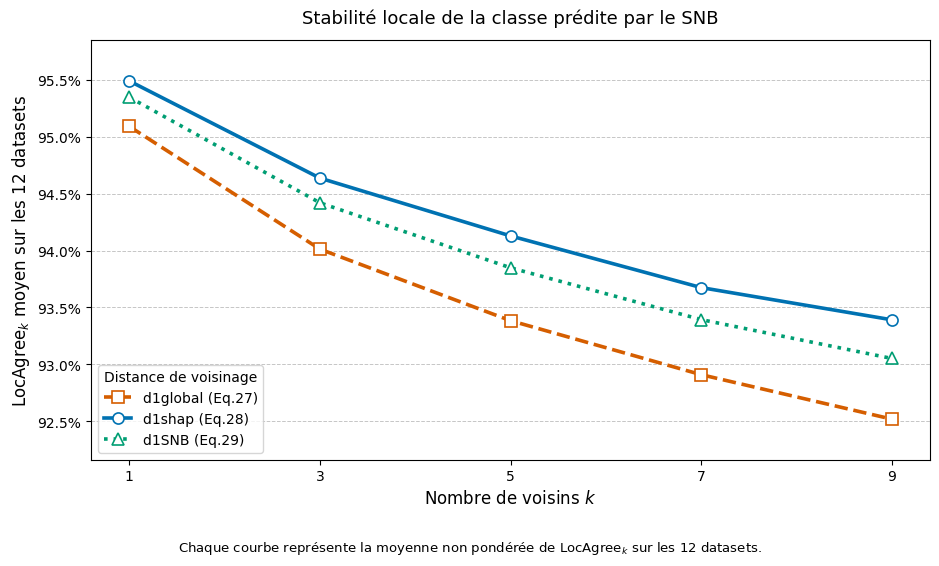


Fichiers créés :
 - khiops_outputs\global_local_agree\local_agree_by_dataset_long.csv
 - khiops_outputs\global_local_agree\local_agree_mean_by_k_and_method.csv
 - khiops_outputs\global_local_agree\local_agree_mean_std_by_k_and_method.csv
 - khiops_outputs\global_local_agree\local_agree_by_k_mean_12_datasets_no_sem.png


In [18]:
# ============================================================
# FIGURE : LocAgree_k MOYEN EN FONCTION DE k
#
# Cette cellule utilise directement `locagree_fold_results`,
# produit dans l'Item 13.
#
# Les courbes représentent la moyenne non pondérée sur les
# 12 datasets, après agrégation pondérée sur les folds de
# chaque dataset.
#
# Aucune bande d'incertitude / SEM n'est affichée.
# Une valeur LocAgree élevée est préférable.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


# ------------------------------------------------------------
# VERIFICATION : L'ITEM 13 DOIT ETRE EXECUTE
# ------------------------------------------------------------

if "locagree_fold_results" not in globals():
    raise RuntimeError(
        "La variable 'locagree_fold_results' est absente.\n\n"
        "Exécutez d'abord l'Item 13, qui calcule LocAgree."
    )

required_columns = {
    "dataset",
    "fold",
    "representation",
    "method",
    "k",
    "n_train",
    "n_test",
    "locagree",
}

missing_columns = required_columns - set(
    locagree_fold_results.columns
)

if missing_columns:
    raise ValueError(
        "Colonnes absentes dans 'locagree_fold_results' :\n"
        f"{sorted(missing_columns)}"
    )


# ------------------------------------------------------------
# PARAMETRES
# ------------------------------------------------------------

LOCAGREE_OUTPUT_DIR = (
    OUTPUT_ROOT_DIR
    / "global_local_agree"
)

LOCAGREE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAGREE_K_VALUES = sorted(
    locagree_fold_results["k"]
    .astype(int)
    .unique()
    .tolist()
)

EXPECTED_METHODS_LOCAGREE = [
    "d1global (Eq.27)",
    "d1shap (Eq.28)",
    "d1SNB (Eq.29)",
]

# Couleurs et styles des trois distances.
PLOT_STYLES_LOCAGREE = {
    "d1global (Eq.27)": {
        "color": "#D55E00",      # orange
        "linestyle": "--",
        "marker": "s",
    },
    "d1shap (Eq.28)": {
        "color": "#0072B2",      # bleu
        "linestyle": "-",
        "marker": "o",
    },
    "d1SNB (Eq.29)": {
        "color": "#009E73",      # vert
        "linestyle": ":",
        "marker": "^",
    },
}

# Axe vertical resserré automatiquement autour des valeurs
# observées afin de mieux distinguer les courbes.
USE_ADAPTIVE_Y_AXIS = True

# Marge minimale ajoutée autour du minimum et du maximum.
MIN_Y_PADDING = 0.003


# ------------------------------------------------------------
# CONTROLES DE COHERENCE
# ------------------------------------------------------------

found_methods = set(
    locagree_fold_results["method"]
    .unique()
    .tolist()
)

missing_methods = (
    set(EXPECTED_METHODS_LOCAGREE)
    - found_methods
)

if missing_methods:
    raise ValueError(
        "Méthodes LocAgree manquantes :\n"
        f"{sorted(missing_methods)}"
    )

expected_datasets = [
    dataset["name"]
    for dataset in DATASETS
]

found_datasets = set(
    locagree_fold_results["dataset"]
    .unique()
    .tolist()
)

missing_datasets = (
    set(expected_datasets)
    - found_datasets
)

if missing_datasets:
    raise ValueError(
        "Datasets absents des résultats LocAgree :\n"
        f"{sorted(missing_datasets)}"
    )


# ------------------------------------------------------------
# AGRÉGATION PAR DATASET
#
# Pour un dataset, la moyenne des folds est pondérée par la
# taille du fold test : chaque observation a le même poids.
# ------------------------------------------------------------

locagree_dataset_rows = []

for (
    dataset_name,
    method_name,
    k_value,
), group in locagree_fold_results.groupby(
    ["dataset", "method", "k"],
    sort=True,
):

    locagree_weighted_mean = np.average(
        group["locagree"],
        weights=group["n_test"],
    )

    locagree_dataset_rows.append(
        {
            "dataset": dataset_name,
            "method": method_name,
            "k": int(k_value),
            "locagree_mean_test": float(
                locagree_weighted_mean
            ),
            "n_test_total": int(
                group["n_test"].sum()
            ),
            "n_folds": int(
                group["fold"].nunique()
            ),
        }
    )

locagree_by_dataset_figure = pd.DataFrame(
    locagree_dataset_rows
)

locagree_by_dataset_figure = (
    locagree_by_dataset_figure
    .sort_values(
        by=[
            "k",
            "dataset",
            "method",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# AGRÉGATION ENTRE DATASETS
#
# Moyenne non pondérée entre les 12 datasets : chaque dataset
# contribue autant, quelle que soit sa taille.
# ------------------------------------------------------------

locagree_global_curve = (
    locagree_by_dataset_figure
    .groupby(
        ["method", "k"],
        as_index=False,
    )
    .agg(
        locagree_mean_datasets=(
            "locagree_mean_test",
            "mean",
        ),
        locagree_std_datasets=(
            "locagree_mean_test",
            "std",
        ),
        n_datasets=(
            "dataset",
            "nunique",
        ),
    )
)

locagree_global_curve = (
    locagree_global_curve
    .sort_values(
        by=[
            "method",
            "k",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# TABLEAU DES VALEURS MOYENNES
# ------------------------------------------------------------

locagree_curve_table = (
    locagree_global_curve
    .pivot(
        index="k",
        columns="method",
        values="locagree_mean_datasets",
    )
)

locagree_curve_table = locagree_curve_table[
    EXPECTED_METHODS_LOCAGREE
]

locagree_curve_table.index.name = "k"

print("=" * 100)
print("LocAgree MOYEN SUR LES 12 DATASETS")
print("=" * 100)
print(
    "Une valeur élevée indique que les voisins partagent "
    "plus fréquemment la même classe prédite par le SNB."
)

display(
    locagree_curve_table
    .mul(100)
    .round(3)
)


# ------------------------------------------------------------
# FIGURE SANS SEM
# ------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(9.5, 5.8),
    facecolor="white",
)

for method_name in EXPECTED_METHODS_LOCAGREE:

    current_curve = locagree_global_curve[
        locagree_global_curve["method"] == method_name
    ].sort_values("k")

    style = PLOT_STYLES_LOCAGREE[method_name]

    axis.plot(
        current_curve["k"],
        current_curve["locagree_mean_datasets"],
        label=method_name,
        color=style["color"],
        linestyle=style["linestyle"],
        marker=style["marker"],
        linewidth=2.6,
        markersize=8,
        markeredgewidth=1.2,
        markeredgecolor=style["color"],
        markerfacecolor="white",
        zorder=2,
    )


# ------------------------------------------------------------
# MISE EN FORME DES AXES
# ------------------------------------------------------------

axis.set_xlabel(
    "Nombre de voisins $k$",
    fontsize=12,
)

axis.set_ylabel(
    r"$\mathrm{LocAgree}_k$ moyen sur les 12 datasets",
    fontsize=12,
)

axis.set_title(
    "Stabilité locale de la classe prédite par le SNB",
    fontsize=13,
    pad=12,
)

axis.set_xticks(LOCAGREE_K_VALUES)

# Affichage de l'axe vertical en pourcentages.
axis.yaxis.set_major_formatter(
    PercentFormatter(
        xmax=1.0,
        decimals=1,
    )
)

# Axe vertical resserré, sans tenir compte d'une SEM.
if USE_ADAPTIVE_Y_AXIS:

    y_min = locagree_global_curve[
        "locagree_mean_datasets"
    ].min()

    y_max = locagree_global_curve[
        "locagree_mean_datasets"
    ].max()

    y_range = y_max - y_min

    y_padding = max(
        MIN_Y_PADDING,
        0.12 * y_range,
    )

    axis.set_ylim(
        max(0.0, y_min - y_padding),
        min(1.0, y_max + y_padding),
    )

else:
    # Variante fixe, si souhaitée pour l'article.
    axis.set_ylim(0.90, 1.00)

axis.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    color="gray",
    alpha=0.45,
)

axis.legend(
    title="Distance de voisinage",
    frameon=True,
    loc="lower left",
    fontsize=10,
    title_fontsize=10,
)

figure.text(
    0.5,
    0.01,
    (
        r"Chaque courbe représente la moyenne non pondérée de "
        r"$\mathrm{LocAgree}_k$ sur les 12 datasets."
    ),
    ha="center",
    fontsize=9.5,
)

figure.tight_layout(
    rect=[0, 0.06, 1, 0.97],
)

plt.show()


# ------------------------------------------------------------
# EXPORTS
# ------------------------------------------------------------

locagree_by_dataset_path = (
    LOCAGREE_OUTPUT_DIR
    / "local_agree_by_dataset_long.csv"
)

locagree_curve_table_path = (
    LOCAGREE_OUTPUT_DIR
    / "local_agree_mean_by_k_and_method.csv"
)

locagree_curve_details_path = (
    LOCAGREE_OUTPUT_DIR
    / "local_agree_mean_std_by_k_and_method.csv"
)

locagree_figure_path = (
    LOCAGREE_OUTPUT_DIR
    / "local_agree_by_k_mean_12_datasets_no_sem.png"
)

locagree_by_dataset_figure.to_csv(
    locagree_by_dataset_path,
    sep=";",
    index=False,
)

locagree_curve_table.to_csv(
    locagree_curve_table_path,
    sep=";",
    index=True,
)

locagree_global_curve.to_csv(
    locagree_curve_details_path,
    sep=";",
    index=False,
)

figure.savefig(
    locagree_figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    edgecolor="white",
)

plt.close(figure)

print("\nFichiers créés :")
print(f" - {locagree_by_dataset_path}")
print(f" - {locagree_curve_table_path}")
print(f" - {locagree_curve_details_path}")
print(f" - {locagree_figure_path}")
